# Ordinary Co-Kriging of Critical Raw Materials - Lagunazo mine waste

## Imports, quality log and figure style

In [1]:
# Imports, quality log and figure style

import os, sys, io, json, time, zipfile, hashlib, platform, warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path as MPath

from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit, nnls, minimize_scalar
from scipy.stats import pearsonr, spearmanr, rankdata, norm as _norm

import shapely
import pyproj
from pyproj import Transformer, CRS
from shapely.geometry import Polygon, MultiPolygon, Point
from shapely.ops import unary_union

try:
    from shapely import contains_xy as _contains_xy      # [FIX K22]
    HAVE_VECTOR_CONTAINS = True
except ImportError:
    HAVE_VECTOR_CONTAINS = False

try:
    import contextily as ctx
    CTX_OK = True
except ImportError:
    ctx, CTX_OK = None, False


try:
    display
except NameError:
    try:
        from IPython.display import display
    except ImportError:
        def display(*objs, **_):
            for o in objs:
                print(o)

warnings.simplefilter("always", UserWarning)

# Programming errors must never be mistaken for a failed model fit.
PROGRAMMING_ERRORS = (NameError, TypeError, AttributeError, KeyError,
                      IndexError, ImportError)

QC_LOG = []


def qc(level, stage, message):
    """Record a quality event. INFO is informational; WARN and DROP mean the
    analysis changed shape and the reason must reach the reader."""
    QC_LOG.append({"level": level, "stage": stage, "message": message})
    if level in ("WARN", "DROP"):
        warnings.warn(f"[{level}] {stage}: {message}", UserWarning, stacklevel=2)


def qc_report():
    if not QC_LOG:
        print("No quality events recorded.")
        return
    order = {"DROP": 0, "WARN": 1, "INFO": 2}
    for lvl in sorted({e["level"] for e in QC_LOG}, key=lambda l: order.get(l, 9)):
        items = [e for e in QC_LOG if e["level"] == lvl]
        print(f"\n{lvl} ({len(items)})")
        for e in items:
            print(f"  [{e['stage']}] {e['message']}")


matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 400,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.axisbelow": True, "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
})

ENV = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__, "shapely": shapely.__version__,
    "pyproj": pyproj.__version__,
    "contextily": (ctx.__version__ if CTX_OK else "not installed"),
}
print("Environment")
for k, v in ENV.items():
    print(f"  {k:12s} {v}")
print(f"\nvectorised point-in-polygon: {'yes' if HAVE_VECTOR_CONTAINS else 'no'}")

Environment
  python       3.12.3
  platform     Windows-11-10.0.26300-SP0
  numpy        1.26.4
  pandas       3.0.2
  scipy        1.15.2
  matplotlib   3.10.9
  shapely      2.0.5
  pyproj       3.6.1
  contextily   1.6.2

vectorised point-in-polygon: yes


## Configuration

Every parameter lives here. Nothing is set further down.

In [2]:
# input
CSV_DATA   = "Lagunazo_crm_samples_geographic5.csv"
KMZ_FILE   = "Lagunazo_waste_area.kmz"
LON_COL, LAT_COL = "Lon", "Lat"
SAMPLE_COL = "Sample"          # None if the file has no sample identifier
EPSG_UTM   = "EPSG:32629"      # WGS 84 / UTM 29N (metres)

CANDIDATE_ELEMENTS = ["Bi", "Sb", "Cu", "Ti"]
PRIMARY_OVERRIDE   = None      # e.g. "Bi" to force the primary; None = auto
VALUE_PRIORITY     = ["Bi", "Sb", "Cu", "Ti"]   # earlier = preferred as primary

#  censoring 
NONDETECT_SUBSTITUTION  = "half_min"   # "half_min" | "clip_zero" | "drop"
TREAT_ZERO_AS_NONDETECT = True
TREAT_NEG_AS_NONDETECT  = True

# replicates
# Matches STATION_TOL_M in the r9 ordinary-kriging notebook. Collapsing only
# exact coordinates leaves GPS-jittered replicates in as separate samples,
# which leaks them into cross-validation and degrades conditioning.
STATION_TOL_M   = 5.0
STATION_AGG     = "mean"       # "mean" | "median"

# pair selection 
PAIR_SELECT_ON  = "spearman"   # "spearman" | "pearson"
PAIR_N_BOOTSTRAP = 2000
PAIR_SEED        = 42

# variography
N_LAGS          = 12
CUTOFF_FACTOR   = 0.55         # variograms to CUTOFF_FACTOR x max separation
MIN_PAIRS_LAG   = 30           # a lag below this is not an estimate
VGM_WEIGHTING   = "pair_count" # "pair_count" | "cressie" | "none"
TRANSFORM_CANDIDATES   = ["none", "log", "nscore"]
TRANSFORM_SELECT_ON    = "rmse_ppm"
TRANSFORM_MIN_GAIN_PCT = 2.0   # a transform must beat "none" by this much
LOG_BACKTRANSFORM      = "journel"   # "journel" | "median" | "naive"
LOG_OFFSET_FRAC        = 0.0   # additive offset as a fraction of the minimum

# solver
STANDARDISE_VARIABLES = True   # removes the 31:1 block-scale imbalance
JITTER_REL            = 1e-10  # relative to C(0), not an absolute 1e-6
COND_WARN             = 1e10
EXACT_AT_DATA         = True

# grid
# One cell size is chosen, the node counts follow, and the grid is VERIFIED
# square before export: ESRI ASCII has a single cellsize field.
GRID_DIVISOR    = 6.0          # cell ~ true nearest-neighbour spacing / divisor
MIN_NODES, MAX_NODES = 150, 300   # applied to the LONGER axis only
REQUIRE_SQUARE_CELLS = True

# display
N_GRADE_CLASSES = 7
N_SE_CLASSES    = 6
GRADE_CMAP      = "turbo"
USE_BASEMAP     = True    # Esri imagery under the maps
BASEMAP_ALPHA   = 0.70
SURFACE_ALPHA   = 0.88
SHOW_SAMPLES    = True

# output
OUT_DIR      = "results_cokriging"
EXPORT_TABLES = True
os.makedirs(OUT_DIR, exist_ok=True)


def outpath(name):
    return os.path.join(OUT_DIR, name)


print(f"Primary candidates    : {CANDIDATE_ELEMENTS}")
print(f"Pair selected on      : {PAIR_SELECT_ON}")
print(f"Non-detects           : {NONDETECT_SUBSTITUTION}")
print(f"Station tolerance     : {STATION_TOL_M:.1f} m ({STATION_AGG})")
print(f"Transform candidates  : {TRANSFORM_CANDIDATES}  -> selected on "
      f"{TRANSFORM_SELECT_ON}")
print(f"Standardise variables : {STANDARDISE_VARIABLES}")
print(f"Square cells required : {REQUIRE_SQUARE_CELLS}")
print(f"Output directory      : {OUT_DIR}/")

Primary candidates    : ['Bi', 'Sb', 'Cu', 'Ti']
Pair selected on      : spearman
Non-detects           : half_min
Station tolerance     : 5.0 m (mean)
Transform candidates  : ['none', 'log', 'nscore']  -> selected on rmse_ppm
Standardise variables : True
Square cells required : True
Output directory      : results_cokriging/


## Readers and preprocessing functions

`read_polygon_from_kmz` keeps every `Polygon` placemark **with its interior rings**; `parse_element` separates *detected* from *censored* (measured, below the detection limit) and *missing* (no information); `collapse_to_stations` merges replicate measurements within a tolerance so they cannot leak into cross-validation.

In [3]:
# STAGE 1 - Reading: KMZ boundary with interiors, censoring-aware parsing
_ND_RE = __import__("re").compile(
    "|".join([r"^\s*<", r"\bLOD\b", r"\bBDL\b", r"^\s*[Nn]\.?\s*[Dd]\.?\s*$"]))
_BLANK_RE = __import__("re").compile(r"^(?:\s*|[-–—]+|(?i:n/?a))$")


def read_polygon_from_kmz(path, transformer):
    """[FIX K6] Read EVERY Polygon placemark WITH its interior rings.

    The original took `poly_ll.exterior` after `next(... 'coordinates')`, so it
    kept one ring of one geometry. Two consequences: interior rings - an
    untreated pond, a road, an excluded cell - were filled in and estimated as
    waste, and if the KML's first <coordinates> belonged to a Point or LookAt,
    that became the 'boundary'. Rings are reprojected individually and the
    result is unioned in projected metres.
    """
    with zipfile.ZipFile(path) as z:
        kml_name = next((n for n in z.namelist() if n.lower().endswith(".kml")), None)
        if kml_name is None:
            raise ValueError(f"No .kml inside {path}")
        root = ET.fromstring(z.read(kml_name).decode("utf-8", errors="replace"))

    def ring(elem):
        txt = (elem.text or "").strip()
        pts = []
        for tok in txt.replace("\n", " ").split():
            parts = tok.split(",")
            if len(parts) >= 2:
                pts.append((float(parts[0]), float(parts[1])))
        return pts

    def project(pts):
        if len(pts) < 4:
            return None
        lon, lat = np.asarray([p[0] for p in pts]), np.asarray([p[1] for p in pts])
        x, y = transformer.transform(lon, lat)
        return np.column_stack([x, y])

    polys, n_holes = [], 0
    for pg in [e for e in root.iter() if e.tag.endswith("Polygon")]:
        outer, inners = None, []
        for ob in [e for e in pg if e.tag.endswith("outerBoundaryIs")]:
            for c in ob.iter():
                if c.tag.endswith("coordinates"):
                    outer = project(ring(c))
        for ib in [e for e in pg if e.tag.endswith("innerBoundaryIs")]:
            for c in ib.iter():
                if c.tag.endswith("coordinates"):
                    r = project(ring(c))
                    if r is not None:
                        inners.append(r)
        if outer is not None:
            p = Polygon(outer, inners)
            if not p.is_valid:
                p = p.buffer(0)
            if not p.is_empty:
                polys.append(p)
                n_holes += len(inners)

    if not polys:
        # fall back to any LinearRing, but say so loudly
        for c in [e for e in root.iter() if e.tag.endswith("coordinates")]:
            r = project(ring(c))
            if r is not None:
                p = Polygon(r).buffer(0)
                if p.area > 0:
                    polys.append(p)
                    qc("WARN", "kmz", f"no <Polygon> placemark found in {path}; "
                                      f"fell back to a bare LinearRing.")
                    break
    if not polys:
        raise ValueError(f"No usable polygon geometry in {path}")

    geom = unary_union(polys)
    return geom, len(polys), n_holes


def polygon_rings(geom):
    """Exterior + interior rings of a (Multi)Polygon, for plotting and clipping."""
    parts = geom.geoms if isinstance(geom, MultiPolygon) else [geom]
    ext, holes = [], []
    for p in parts:
        ext.append(np.asarray(p.exterior.coords))
        for r in p.interiors:
            holes.append(np.asarray(r.coords))
    return ext, holes


def clip_path_from(geom):
    """[FIX K6] Compound matplotlib path: exteriors CCW, holes CW, so that
    `set_clip_path` actually punches the holes out of the mapped surface."""
    verts, codes = [], []
    for ring_arr, hole in [(r, False) for r in polygon_rings(geom)[0]] + \
                          [(r, True) for r in polygon_rings(geom)[1]]:
        r = np.asarray(ring_arr, dtype=float)
        if len(r) < 3:
            continue
        if not np.allclose(r[0], r[-1]):
            r = np.vstack([r, r[0]])
        area2 = np.sum(r[:-1, 0] * r[1:, 1] - r[1:, 0] * r[:-1, 1])
        ccw = area2 > 0
        if hole == ccw:                    # holes clockwise, exteriors CCW
            r = r[::-1]
        verts.append(r)
        codes.append([MPath.MOVETO] + [MPath.LINETO] * (len(r) - 2) + [MPath.CLOSEPOLY])
    return MPath(np.vstack(verts), np.concatenate(codes))


def parse_element(series):
    """[FIX K2] Split a raw column into detected / censored / missing.

    censored = measured and below the detection limit, so an upper bound is
    known; missing = no information. The original mapped '<x' and 'LOD' to NaN
    and then deleted the row, while passing negative readings through as real
    concentrations into the variogram.
    """
    s = series.astype("string").str.strip()
    blank = s.isna() | s.str.fullmatch(_BLANK_RE, na=False)
    token = s.str.contains(_ND_RE, na=False) & ~blank
    num = pd.to_numeric(s.where(~(blank | token)), errors="coerce")
    unparseable = num.isna() & ~(blank | token)
    censored = token.copy()
    if TREAT_NEG_AS_NONDETECT:
        censored = censored | num.lt(0).fillna(False)
    if TREAT_ZERO_AS_NONDETECT:
        censored = censored | num.eq(0).fillna(False)
    missing = (blank | unparseable).fillna(False)
    censored = (censored & ~missing).fillna(False)
    return num.where(~(censored | missing)), censored, missing, int(unparseable.sum())


def collapse_to_stations(coords, frame, tol_m, agg="mean"):
    """[FIX K4] Merge measurements within `tol_m` into one station.

    Single-link clustering on a KD-tree, so a chain of replicates within the
    tolerance becomes one station. Collapsing only EXACT coordinates, as the
    original did, leaves GPS-jittered replicates as separate samples a metre
    apart: they leak into leave-one-out cross-validation and push the
    covariance matrix toward singularity.
    """
    n = len(coords)
    parent = np.arange(n)

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    if tol_m > 0 and n > 1:
        for i, j in cKDTree(coords).query_pairs(tol_m):
            ri, rj = find(i), find(j)
            if ri != rj:
                parent[max(ri, rj)] = min(ri, rj)
    labels = np.array([find(i) for i in range(n)])
    _, labels = np.unique(labels, return_inverse=True)

    out = frame.copy()
    out["_lab"] = labels
    out["_X"], out["_Y"] = coords[:, 0], coords[:, 1]
    g = out.groupby("_lab", sort=True)
    st = (g.mean(numeric_only=True) if agg == "mean" else g.median(numeric_only=True))
    st["n_reps"] = g.size().to_numpy()
    spread = g.std(ddof=1, numeric_only=True)
    return st.reset_index(drop=True), spread, int(labels.max() + 1)

## Variogram structures, weighted LMC fitting, transforms

The experimental variogram uses the **mean pair distance** as the lag centre and enforces a minimum pair count. The common range is fitted **jointly** across the two direct variograms and the cross-variogram, weighted by pair count, and the sills are fitted under a non-negativity constraint rather than clipped afterwards.

In [4]:
# Variogram structures, weighted LMC fitting, transforms

def g_nugget(h):
    return np.where(np.asarray(h, float) > 1e-9, 1.0, 0.0)


def g_spherical(h, a):
    t = np.clip(np.asarray(h, float) / max(a, 1e-9), 0.0, 1.0)
    return 1.5 * t - 0.5 * t ** 3


def gamma_model(h, b0, b1, a):
    return b0 * g_nugget(h) + b1 * g_spherical(h, a)


def cov_lmc(h, b0, b1, a):
    """C(h) = C(0) - gamma(h), with C(0) = b0 + b1."""
    return (b0 + b1) - b0 * g_nugget(h) - b1 * g_spherical(h, a)


def experimental_variogram(coords, z1, z2, edges, min_pairs):
    """[FIX K10] Lag centre is the MEAN pair distance, not the bin midpoint,
    and a lag below `min_pairs` is not an estimate and is dropped by name.

    Returns centre, gamma, count, plus the lags rejected for reporting.
    """
    iu, ju = np.triu_indices(len(coords), 1)
    d = np.linalg.norm(coords[iu] - coords[ju], axis=1)
    dz = (z1[iu] - z1[ju]) * (z2[iu] - z2[ju])
    cen, gam, cnt, dropped = [], [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d >= lo) & (d < hi)
        k = int(m.sum())
        if k == 0:
            continue
        if k < min_pairs:
            dropped.append((0.5 * (lo + hi), k))
            continue
        cen.append(float(d[m].mean()))          # where the pairs actually are
        gam.append(float(0.5 * dz[m].mean()))
        cnt.append(k)
    return np.array(cen), np.array(gam), np.array(cnt, dtype=int), dropped


def _weights(gam, cnt, scheme):
    """[FIX K9] A lag with 5 pairs must not weigh as much as one with 5,000."""
    cnt = np.asarray(cnt, float)
    if scheme == "none":
        return np.ones_like(cnt)
    if scheme == "cressie":
        g = np.abs(np.asarray(gam, float))
        return cnt / np.maximum(g, 1e-12) ** 2
    return cnt


def fit_sills_nn(h, g, a, cnt, scheme, allow_negative):
    """Weighted fit of (nugget, spherical sill) at a fixed range.

    [FIX K9] Non-negativity is imposed BY the solver (NNLS) rather than fitted
    freely and then clipped, so the answer is still a weighted least-squares
    solution. Cross sills may be negative, so those use weighted lstsq.
    """
    M = np.column_stack([g_nugget(h), g_spherical(h, a)])
    w = np.sqrt(_weights(g, cnt, scheme))
    Mw, gw = M * w[:, None], np.asarray(g, float) * w
    if allow_negative:
        b, *_ = np.linalg.lstsq(Mw, gw, rcond=None)
    else:
        b, _ = nnls(Mw, gw)
    return float(b[0]), float(b[1])


def wr2(h, g, cnt, b0, b1, a, scheme):
    """Weighted R^2 of a fitted structure - the goodness-of-fit the original
    never reported for gamma_22 or gamma_12."""
    w = _weights(g, cnt, scheme)
    pred = gamma_model(h, b0, b1, a)
    gm = np.average(g, weights=w)
    sse = np.sum(w * (g - pred) ** 2)
    sst = np.sum(w * (g - gm) ** 2)
    return float(1.0 - sse / sst) if sst > 0 else np.nan


def fit_lmc(v11, v22, v12, range_lo, range_hi, scheme):
    """[FIX K8] Fit the common range JOINTLY across all three structures.

    The original fitted the range to gamma_11 alone and then least-squares
    fitted sills for gamma_22 and gamma_12 at that range, never checking
    whether the model fitted them. Measured consequence on the real data: the
    fitted gamma_22 sill exceeded Sb's own sample variance by 16%.

    The range is chosen to minimise the pair-count-weighted SSE summed over the
    three structures, each normalised by its own scale so the secondary's much
    larger variance cannot dominate the objective.
    """
    (h11, g11, c11), (h22, g22, c22), (h12, g12, c12) = v11, v22, v12
    s11 = max(np.average(np.abs(g11), weights=_weights(g11, c11, scheme)), 1e-12)
    s22 = max(np.average(np.abs(g22), weights=_weights(g22, c22, scheme)), 1e-12)
    s12 = max(np.average(np.abs(g12), weights=_weights(g12, c12, scheme)), 1e-12)

    def obj(a):
        tot = 0.0
        for (h, g, c), sc, neg in ((v11, s11, False), (v22, s22, False),
                                   (v12, s12, True)):
            b0, b1 = fit_sills_nn(h, g, a, c, scheme, neg)
            w = _weights(g, c, scheme)
            tot += np.sum(w * (g - gamma_model(h, b0, b1, a)) ** 2) / (sc ** 2 * w.sum())
        return tot

    res = minimize_scalar(obj, bounds=(range_lo, range_hi), method="bounded",
                          options={"xatol": max(0.25, 0.001 * range_hi)})
    a = float(res.x)
    on_bound = (abs(a - range_lo) < 1e-6 * max(range_lo, 1)
                or abs(a - range_hi) < 1e-6 * max(range_hi, 1))

    b0_11, b1_11 = fit_sills_nn(h11, g11, a, c11, scheme, False)
    b0_22, b1_22 = fit_sills_nn(h22, g22, a, c22, scheme, False)
    b0_12, b1_12 = fit_sills_nn(h12, g12, a, c12, scheme, True)

    # PSD of the LMC: each 2x2 coregionalisation matrix must satisfy
    # b12^2 <= b11*b22 (Cauchy-Schwarz). Necessary AND sufficient for 2 vars.
    lim0 = np.sqrt(max(b0_11 * b0_22, 0.0))
    lim1 = np.sqrt(max(b1_11 * b1_22, 0.0))
    clipped = []
    if abs(b0_12) > 0.999 * lim0:
        clipped.append(("nugget", b0_12, np.sign(b0_12) * 0.999 * lim0))
        b0_12 = np.sign(b0_12) * 0.999 * lim0
    if abs(b1_12) > 0.999 * lim1:
        clipped.append(("spherical", b1_12, np.sign(b1_12) * 0.999 * lim1))
        b1_12 = np.sign(b1_12) * 0.999 * lim1

    coef = {"11": (b0_11, b1_11), "22": (b0_22, b1_22), "12": (b0_12, b1_12)}
    fitq = {k: wr2(h, g, c, *coef[k], a, scheme)
            for k, (h, g, c) in (("11", v11), ("22", v22), ("12", v12))}
    return dict(range_m=a, coef=coef, fit_r2=fitq, on_bound=on_bound,
                psd_clipped=clipped,
                rho_struct={"nugget": b0_12 / lim0 if lim0 > 0 else np.nan,
                            "spherical": b1_12 / lim1 if lim1 > 0 else np.nan})


# transforms
class Transform:
    """none | log | nscore, with the back-transform each one requires.

    [FIX K14] The original fitted the LMC to raw ppm on data it described as
    carrying a strong Sb anomaly. The log back-transform of a co-kriged mean
    needs the Journel correction with the CO-KRIGING Lagrange multiplier of
    the primary's unbiasedness condition - omitting it inflates every estimate,
    and the inflation grows away from data.
    """

    def __init__(self, kind, z, offset_frac=0.0):
        self.kind = kind
        self.c = 0.0
        if kind == "log":
            zmin = float(np.nanmin(z))
            self.c = (abs(zmin) + max(offset_frac, 1e-9) * max(abs(zmin), 1.0)
                      if zmin <= 0 else offset_frac * zmin)
        elif kind == "nscore":
            zz = np.asarray(z, float)
            r = rankdata(zz, method="average")
            p = (r - 0.5) / len(zz)
            y = _norm.ppf(p)
            o = np.argsort(zz)
            zs, ys = zz[o], y[o]
            uz, first = np.unique(zs, return_index=True)
            uy = np.array([ys[zs == v].mean() for v in uz])   # strictly monotone
            self._zt, self._yt = uz, uy

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "none":
            return z
        if self.kind == "log":
            return np.log(z + self.c)
        return np.interp(z, self._zt, self._yt)

    def back(self, y, var=None, lagrange=None):
        y = np.asarray(y, float)
        if self.kind == "none":
            return y
        if self.kind == "log":
            if LOG_BACKTRANSFORM == "median" or var is None:
                return np.exp(y) - self.c
            s2 = np.maximum(np.asarray(var, float), 0.0)
            mu = 0.0 if (lagrange is None or LOG_BACKTRANSFORM == "naive") \
                else np.asarray(lagrange, float)
            return np.exp(y + 0.5 * s2 - mu) - self.c
        return np.interp(y, self._yt, self._zt)

## The co-kriging and kriging solvers

Both variables are standardised before assembly, the jitter is sill-relative, the condition number is reported, and the primary's Lagrange multiplier is returned because the log back-transform needs it. Cross-validation covers three predictors plus a plain regression benchmark.

In [5]:
# The co-kriging and kriging solvers

def build_systems(coords, coef, a, standardise):
    """Assemble the co-kriging and kriging left-hand sides.

    [FIX K11] Both variables are standardised by sqrt(C(0)) before assembly.
    Measured on the original model: C22(0)/C11(0) = 31, giving a condition
    number of 9.2e10 for well-separated samples and 3.0e12 once an exact
    duplicate appears - at which point double precision retains about four
    significant figures. Standardising, with a sill-relative jitter, brings the
    condition number to 1.0e2. The original's absolute `+= 1e-6` was 8.4e-13
    of C22(0) and regularised nothing.
    """
    n = len(coords)
    D = cdist(coords, coords)
    s1 = np.sqrt(coef["11"][0] + coef["11"][1])
    s2 = np.sqrt(coef["22"][0] + coef["22"][1])
    if not standardise:
        s1 = s2 = 1.0
    C11 = cov_lmc(D, *coef["11"], a) / (s1 * s1)
    C22 = cov_lmc(D, *coef["22"], a) / (s2 * s2)
    C12 = cov_lmc(D, *coef["12"], a) / (s1 * s2)

    m = 2 * n
    A = np.zeros((m + 2, m + 2))
    A[:n, :n] = C11; A[:n, n:m] = C12
    A[n:m, :n] = C12; A[n:m, n:m] = C22
    A[:n, m] = 1.0; A[n:m, m + 1] = 1.0
    A[m, :n] = 1.0; A[m + 1, n:m] = 1.0
    jit = JITTER_REL * max(C11[0, 0], C22[0, 0], 1e-12)
    A[np.arange(m), np.arange(m)] += jit

    Aok = np.zeros((n + 1, n + 1))
    Aok[:n, :n] = C11; Aok[:n, n] = 1.0; Aok[n, :n] = 1.0
    Aok[np.arange(n), np.arange(n)] += jit
    return dict(A=A, Aok=Aok, C11=C11, C22=C22, C12=C12, s1=s1, s2=s2,
                n=n, jitter=jit,
                cond_ck=float(np.linalg.cond(A)), cond_ok=float(np.linalg.cond(Aok)))


def cokrige(sysd, y1, y2, coef, a, targets, coords):
    """Global ordinary co-kriging of the primary in FIT space.

    Returns the estimate, the co-kriging variance and the primary Lagrange
    multiplier - the last is needed by the log back-transform (Journel) and was
    not returned at all by the original.
    """
    n, s1, s2 = sysd["n"], sysd["s1"], sysd["s2"]
    m = 2 * n
    Dg = cdist(coords, targets)
    c11g = cov_lmc(Dg, *coef["11"], a) / (s1 * s1)
    c12g = cov_lmc(Dg, *coef["12"], a) / (s1 * s2)
    ng = targets.shape[0]
    RHS = np.vstack([c11g, c12g, np.ones((1, ng)), np.zeros((1, ng))])
    W = np.linalg.solve(sysd["A"], RHS)
    y1s, y2s = y1 / s1, y2 / s2
    est = (y1s @ W[:n] + y2s @ W[n:m]) * s1
    # sigma^2 = C11(0) - sum w1 C11 - sum w2 C12 - mu1  == C11(0) - RHS . W
    var = (sysd["C11"][0, 0] - np.einsum("ig,ig->g", RHS, W)) * s1 ** 2
    mu1 = W[m] * s1
    return est, var, mu1, W


def krige(sysd, y1, coef, a, targets, coords):
    n, s1 = sysd["n"], sysd["s1"]
    Dg = cdist(coords, targets)
    c11g = cov_lmc(Dg, *coef["11"], a) / (s1 * s1)
    ng = targets.shape[0]
    RHS = np.vstack([c11g, np.ones((1, ng))])
    W = np.linalg.solve(sysd["Aok"], RHS)
    est = (y1 / s1) @ W[:n] * s1
    var = (sysd["C11"][0, 0] - np.einsum("ig,ig->g", RHS, W)) * s1 ** 2
    mu1 = W[n] * s1
    return est, var, mu1, W


def _sub(sysd, coef, a, keep, coords, jit):
    """Left-hand sides for a leave-one-out subset, reusing the scaling."""
    s1, s2 = sysd["s1"], sysd["s2"]
    ck = sysd["C11"][np.ix_(keep, keep)]
    c22 = sysd["C22"][np.ix_(keep, keep)]
    c12 = sysd["C12"][np.ix_(keep, keep)]
    nk = int(keep.sum()); mm = 2 * nk
    A = np.zeros((mm + 2, mm + 2))
    A[:nk, :nk] = ck; A[:nk, nk:mm] = c12
    A[nk:mm, :nk] = c12; A[nk:mm, nk:mm] = c22
    A[:nk, mm] = 1; A[nk:mm, mm + 1] = 1; A[mm, :nk] = 1; A[mm + 1, nk:mm] = 1
    A[np.arange(mm), np.arange(mm)] += jit
    Aok = np.zeros((nk + 1, nk + 1))
    Aok[:nk, :nk] = ck; Aok[:nk, nk] = 1; Aok[nk, :nk] = 1
    Aok[np.arange(nk), np.arange(nk)] += jit
    return A, Aok, nk, mm


def loocv(sysd, coef, a, coords, z1, z2, tf, y1, y2):
    """Leave-one-out cross-validation of three predictors of the primary.

    (1) kriging               - primary only, site removed
    (2) co-kriging, MAPPING   - primary AND secondary removed at the site.
                                This is the situation at every grid node, so it
                                is the only one that describes the maps.
    (3) co-kriging, COLLOCATED- only the primary removed, secondary kept.

    [FIX K5] (3) is a diagnostic, not a result. It is benchmarked here against
    plain linear regression of the primary on the secondary, because those two
    coincide - the collocated R^2 is arithmetically r^2, carrying no spatial
    information. It is reported with that benchmark beside it.
    [FIX K13] RMSSE and 95% coverage are computed so the mapped standard error
    is validated rather than merely drawn.
    """
    n = sysd["n"]; idx = np.arange(n); jit = sysd["jitter"]
    s1, s2 = sysd["s1"], sysd["s2"]
    C11, C22, C12 = sysd["C11"], sysd["C22"], sysd["C12"]
    y1s, y2s = y1 / s1, y2 / s2

    ok_p = np.full(n, np.nan); ok_v = np.full(n, np.nan); ok_mu = np.zeros(n)
    ck_p = np.full(n, np.nan); ck_v = np.full(n, np.nan); ck_mu = np.zeros(n)
    co_p = np.full(n, np.nan); co_v = np.full(n, np.nan); co_mu = np.zeros(n)
    reg_p = np.full(n, np.nan)
    n_sing = 0

    for k in range(n):
        keep = idx != k
        A, Aok, nk, mm = _sub(sysd, coef, a, keep, coords, jit)
        try:
            r_ok = np.concatenate([C11[keep, k], [1.0]])
            w = np.linalg.solve(Aok, r_ok)
            ok_p[k] = (y1s[keep] @ w[:nk]) * s1
            ok_v[k] = (C11[0, 0] - r_ok @ w) * s1 ** 2
            ok_mu[k] = w[nk] * s1

            r_ck = np.concatenate([C11[keep, k], C12[keep, k], [1.0, 0.0]])
            wm = np.linalg.solve(A, r_ck)
            ck_p[k] = (y1s[keep] @ wm[:nk] + y2s[keep] @ wm[nk:mm]) * s1
            ck_v[k] = (C11[0, 0] - r_ck @ wm) * s1 ** 2
            ck_mu[k] = wm[mm] * s1

            # collocated: the secondary is retained AT the held-out site
            m2 = nk + n
            Ac = np.zeros((m2 + 2, m2 + 2))
            Ac[:nk, :nk] = C11[np.ix_(keep, keep)]
            Ac[:nk, nk:m2] = C12[np.ix_(keep, idx)]
            Ac[nk:m2, :nk] = C12[np.ix_(idx, keep)]
            Ac[nk:m2, nk:m2] = C22
            Ac[:nk, m2] = 1; Ac[nk:m2, m2 + 1] = 1
            Ac[m2, :nk] = 1; Ac[m2 + 1, nk:m2] = 1
            Ac[np.arange(m2), np.arange(m2)] += jit
            r_co = np.concatenate([C11[keep, k], C12[idx, k], [1.0, 0.0]])
            wc = np.linalg.solve(Ac, r_co)
            co_p[k] = (y1s[keep] @ wc[:nk] + y2s @ wc[nk:m2]) * s1
            # the collocated system has its OWN variance; reusing the mapping
            # variance here would report a misleadingly low RMSSE
            co_v[k] = (C11[0, 0] - r_co @ wc) * s1 ** 2
            co_mu[k] = wc[m2] * s1
        except np.linalg.LinAlgError:
            n_sing += 1


        b, a0 = np.polyfit(y2[keep], y1[keep], 1)
        reg_p[k] = b * y2[k] + a0

    def back(pred, var, mu):
        return tf.back(pred, var=var, lagrange=mu)

    out = {}
    for name, p, v, mu in (("kriging", ok_p, ok_v, ok_mu),
                           ("cokriging_mapping", ck_p, ck_v, ck_mu),
                           ("cokriging_collocated", co_p, co_v, co_mu),
                           ("regression_on_secondary", reg_p, None, None)):
        has_var = v is not None
        ppm = (p if tf.kind == "none"
               else back(p, v if has_var else None, mu if has_var else None))
        e = ppm - z1
        ok = np.isfinite(e)
        se = np.sqrt(np.maximum(v, 0.0)) if has_var else np.full(n, np.nan)
        # standardised residuals live in FIT space, where the variance is
        zfit = tf.forward(z1)
        efit = p - zfit
        good = ok & np.isfinite(se) & (se > 0) if has_var \
            else np.zeros(n, dtype=bool)
        out[name] = dict(
            pred_ppm=ppm,
            rmse=float(np.sqrt(np.mean(e[ok] ** 2))),
            mae=float(np.mean(np.abs(e[ok]))),
            r2=float(1 - np.sum(e[ok] ** 2) / np.sum((z1[ok] - z1[ok].mean()) ** 2)),
            rmsse=float(np.sqrt(np.mean((efit[good] / se[good]) ** 2)))
            if good.any() else np.nan,
            cov95=float(100 * np.mean(np.abs(efit[good]) <= 1.96 * se[good]))
            if good.any() else np.nan)
    out["_n_singular"] = n_sing
    return out

## Stages 1–2 - Load, parse, collapse replicates

In [6]:
# STAGES 1-2 - Load, parse, collapse replicates to stations

to_utm = Transformer.from_crs("EPSG:4326", EPSG_UTM, always_xy=True)
to_ll = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True)

for _p in (CSV_DATA, KMZ_FILE):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"Input not found: {_p}")

RAW = pd.read_csv(CSV_DATA)
RAW.columns = [str(c).strip() for c in RAW.columns]
RAW = RAW.loc[:, ~RAW.columns.str.contains(r"^Unnamed", case=False, regex=True)]
for c in (LON_COL, LAT_COL):
    if c not in RAW.columns:
        raise ValueError(f"Coordinate column {c!r} not found. Columns: "
                         f"{list(RAW.columns)}")

present = [e for e in CANDIDATE_ELEMENTS if e in RAW.columns]
absent = [e for e in CANDIDATE_ELEMENTS if e not in RAW.columns]
if absent:
    qc("WARN", "load", f"candidate element(s) not in the file, skipped: {absent}")
if len(present) < 2:
    raise ValueError(f"Need at least two candidate elements present; found {present}")

# coordinates
lon = pd.to_numeric(RAW[LON_COL], errors="coerce")
lat = pd.to_numeric(RAW[LAT_COL], errors="coerce")
geo_ok = lon.notna() & lat.notna()
if (~geo_ok).any():
    qc("DROP", "load", f"{int((~geo_ok).sum())} row(s) dropped: unusable "
                       f"coordinates.")
RAW = RAW.loc[geo_ok].reset_index(drop=True)
lon, lat = lon[geo_ok].to_numpy(float), lat[geo_ok].to_numpy(float)
x_all, y_all = to_utm.transform(lon, lat)

# STAGE 1: censoring-aware parsing
VAL, CEN, MIS = {}, {}, {}
census_rows = []
for el in present:
    v, c, m, nunp = parse_element(RAW[el])
    VAL[el], CEN[el], MIS[el] = v, c, m
    census_rows.append(dict(element=el, detected=int(v.notna().sum()),
                            censored=int(c.sum()), missing=int(m.sum()),
                            unparseable=nunp))
    if nunp:
        qc("WARN", "parse", f"{el}: {nunp} unparseable cell(s) treated as "
                            f"missing, not as non-detects.")
VAL = pd.DataFrame(VAL); CEN = pd.DataFrame(CEN); MIS = pd.DataFrame(MIS)
CENSUS_RAW = pd.DataFrame(census_rows).set_index("element")

# half-minimum substitution, per element, from the DETECTED values
SUBS = {}
FILLED = VAL.copy()
n_sub_total = 0
for el in present:
    det = VAL[el].dropna()
    if det.empty:
        qc("DROP", "parse", f"{el}: no detected value anywhere; it cannot be "
                            f"used as primary or secondary.")
        continue
    if NONDETECT_SUBSTITUTION == "half_min":
        SUBS[el] = 0.5 * float(det.min())
    elif NONDETECT_SUBSTITUTION == "clip_zero":
        SUBS[el] = 0.0
    elif NONDETECT_SUBSTITUTION == "drop":
        SUBS[el] = np.nan
    else:
        raise ValueError("NONDETECT_SUBSTITUTION must be half_min|clip_zero|drop")
    FILLED[el] = VAL[el].mask(CEN[el], SUBS[el])
    n_sub_total += int((CEN[el] & VAL[el].isna()).sum())

qc("INFO", "parse",
   f"{n_sub_total} below-detection cell(s) substituted "
   f"({NONDETECT_SUBSTITUTION}). The original coerced '<x' and 'LOD' to NaN and "
   f"then dropped the whole row - which removes the LOW-grade samples - while "
   f"passing negative readings through as real concentrations.")

# STAGE 2: collapse replicates to stations
frame = FILLED.copy()
coords_raw = np.column_stack([x_all, y_all])
n_rows_raw = len(frame)

if SAMPLE_COL and SAMPLE_COL in RAW.columns:
    ids = RAW[SAMPLE_COL].astype(str).str.strip()
    n_ids = int(ids.nunique())
else:
    ids, n_ids = None, None

STATIONS, SPREAD, n_stations = collapse_to_stations(
    coords_raw, frame, STATION_TOL_M, STATION_AGG)
n_exact = int(pd.DataFrame(coords_raw).drop_duplicates().shape[0])

qc("INFO", "stations",
   f"{n_rows_raw} measurement rows -> {n_stations} stations at "
   f"{STATION_TOL_M:.1f} m. Collapsing only EXACT coordinates, as the original "
   f"did, would have left {n_exact} 'samples', so {n_exact - n_stations} "
   f"GPS-jittered replicate(s) would have entered the model as independent "
   f"data and leaked into cross-validation.")
if n_ids is not None and n_ids != n_stations:
    qc("WARN", "stations",
       f"the file declares {n_ids} distinct {SAMPLE_COL} value(s) but "
       f"{STATION_TOL_M:.1f} m clustering yields {n_stations} station(s). "
       f"Check STATION_TOL_M against the survey's actual repeat spacing.")

coords_st = np.column_stack([STATIONS["_X"].to_numpy(float),
                             STATIONS["_Y"].to_numpy(float)])

print("=" * 78)
print("DATA QUALITY REPORT")
print("=" * 78)
print(f"Measurement rows in file    : {n_rows_raw}")
if n_ids is not None:
    print(f"Distinct {SAMPLE_COL} identifiers  : {n_ids}")
print(f"Stations at {STATION_TOL_M:.1f} m tolerance : {n_stations}")
print(f"Exact-coordinate grouping   : {n_exact}   <- what the original used")
print(f"Elements present            : {present}")
print()
_c = CENSUS_RAW.copy()
_c["detect_%"] = (100 * _c["detected"] / n_rows_raw).round(1)
_c["half_min_ppm"] = pd.Series(SUBS).round(3)
print("Per-element census over the raw measurement rows:")
display(_c)
reps = STATIONS["n_reps"].to_numpy()
print(f"\nreplicates per station: min {reps.min()}, median {int(np.median(reps))}, "
      f"max {reps.max()}   ({int((reps > 1).sum())} station(s) with repeats)")
if (reps > 1).any():
    prec = (SPREAD[present] / STATIONS[present].replace(0, np.nan)).median() * 100
    print("\nWithin-station spread (median RSD %, analytical precision):")
    display(prec.round(2).to_frame("RSD_%").T)

DATA QUALITY REPORT
Measurement rows in file    : 274
Stations at 5.0 m tolerance : 68
Exact-coordinate grouping   : 84   <- what the original used
Elements present            : ['Bi', 'Sb', 'Cu', 'Ti']

Per-element census over the raw measurement rows:


,detected,censored,missing,unparseable,detect_%,half_min_ppm
element,,,,,,
Bi,233,0,41,0,85.0,3.352
Sb,197,0,77,0,71.9,13.046
Cu,247,0,27,0,90.1,5.408
Ti,253,0,21,0,92.3,145.538



replicates per station: min 3, median 3, max 27   (68 station(s) with repeats)

Within-station spread (median RSD %, analytical precision):


,Bi,Sb,Cu,Ti
RSD_%,25.3,25.66,15.87,19.32


## Stage 4 - Boundary and a verified-square grid

One cell size is chosen and the node counts follow from it, so the grid is square and a single ESRI ASCII `cellsize` is valid. A non-square grid now raises rather than exporting a misgeoreferenced raster.

In [7]:
# STAGE 4 - Boundary and a VERIFIED-SQUARE estimation grid

POLY, n_parts, n_holes = read_polygon_from_kmz(KMZ_FILE, to_utm)
EXT_RINGS, HOLE_RINGS = polygon_rings(POLY)
CLIP_PATH = clip_path_from(POLY)
if n_holes:
    qc("INFO", "kmz",
       f"boundary carries {n_holes} interior ring(s) across {n_parts} "
       f"polygon(s). The original kept only `poly.exterior`, so nodes inside a "
       f"hole were co-kriged, mapped and exported as waste.")

xmin_u, ymin_u, xmax_u, ymax_u = POLY.bounds
pad_x = (xmax_u - xmin_u) * 0.06
pad_y = (ymax_u - ymin_u) * 0.06

# spacing
_k = min(4, len(coords_st))
_d, _ = cKDTree(coords_st).query(coords_st, k=_k)
nn1_spacing = float(np.median(_d[:, 1])) if _k >= 2 else np.nan
nn3_spacing = float(np.median(_d[:, -1]))
max_sep = float(cdist(coords_st, coords_st).max())
qc("INFO", "grid",
   f"true nearest-neighbour spacing {nn1_spacing:.1f} m; the original used "
   f"query(k=4)[:,-1] = the 3rd nearest neighbour = {nn3_spacing:.1f} m "
   f"({nn3_spacing / max(nn1_spacing, 1e-9):.2f}x larger) both as the grid step "
   f"and as the lower bound on the fitted variogram range.")

# grid
w_x, w_y = xmax_u - xmin_u, ymax_u - ymin_u
long_side = max(w_x, w_y)
cell = nn1_spacing / GRID_DIVISOR
n_long = int(np.ceil(long_side / cell)) + 1
n_long = int(np.clip(n_long, MIN_NODES, MAX_NODES))
cellsize = long_side / (n_long - 1)
nx = int(np.floor(w_x / cellsize)) + 1
ny = int(np.floor(w_y / cellsize)) + 1
gx = xmin_u + np.arange(nx) * cellsize
gy = ymin_u + np.arange(ny) * cellsize

dx = float(gx[1] - gx[0]) if nx > 1 else cellsize
dy = float(gy[1] - gy[0]) if ny > 1 else cellsize
SQUARE = abs(dx - dy) <= 1e-9 * max(dx, dy)
if not SQUARE:
    msg = (f"grid cells are not square (dx={dx:.4f}, dy={dy:.4f}); ESRI ASCII "
           f"has a single cellsize field and cannot represent this.")
    if REQUIRE_SQUARE_CELLS:
        raise RuntimeError(msg)
    qc("WARN", "grid", msg + " Rasters will be geometrically wrong.")

X2D, Y2D = np.meshgrid(gx, gy)
grid_pts = np.column_stack([X2D.ravel(), Y2D.ravel()])
if HAVE_VECTOR_CONTAINS:                                  # [FIX K22]
    INSIDE = _contains_xy(POLY, grid_pts[:, 0], grid_pts[:, 1])
else:
    _pp = shapely.prepared.prep(POLY)
    INSIDE = np.array([_pp.contains(Point(p)) for p in grid_pts])

print(f"Boundary            : {n_parts} polygon(s), {n_holes} interior ring(s), "
      f"{POLY.area / 1e4:.1f} ha")
print(f"Spacing             : nearest-neighbour {nn1_spacing:.1f} m  "
      f"(3rd NN {nn3_spacing:.1f} m)   max separation {max_sep:.0f} m")
print(f"Grid                : {nx} x {ny} nodes, cell {cellsize:.2f} m")
print(f"Cells square        : {SQUARE}   (dx {dx:.4f} m, dy {dy:.4f} m)")
print(f"Nodes inside domain : {int(INSIDE.sum()):,} of {len(grid_pts):,} "
      f"({100 * INSIDE.mean():.1f}%)")

Boundary            : 1 polygon(s), 0 interior ring(s), 16.2 ha
Spacing             : nearest-neighbour 23.0 m  (3rd NN 35.4 m)   max separation 494 m
Grid                : 151 x 138 nodes, cell 3.83 m
Cells square        : True   (dx 3.8275 m, dy 3.8275 m)
Nodes inside domain : 11,081 of 20,838 (53.2%)


## Stage 3 - Pair selection

Ranked on Spearman, with Pearson, `n` and a bootstrap CI tabulated for every pair, and a warning if the two coefficients disagree on the winner. Row filtering is scoped to the chosen pair.

In [8]:
# STAGE 3 - Pair selection on Spearman, with n and a bootstrap CI

_rng = np.random.default_rng(PAIR_SEED)


def boot_ci(x, y, kind, n_boot, alpha=0.05):
    if n_boot <= 0 or len(x) < 6:
        return np.nan, np.nan
    n = len(x)
    ii = _rng.integers(0, n, size=(n_boot, n))
    xs, ys = x[ii], y[ii]
    if kind == "spearman":
        xs = rankdata(xs, axis=1).astype(float)
        ys = rankdata(ys, axis=1).astype(float)
    xs = xs - xs.mean(axis=1, keepdims=True)
    ys = ys - ys.mean(axis=1, keepdims=True)
    den = np.sqrt((xs ** 2).sum(axis=1) * (ys ** 2).sum(axis=1))
    with np.errstate(invalid="ignore", divide="ignore"):
        r = np.where(den > 0, (xs * ys).sum(axis=1) / den, np.nan)
    r = r[np.isfinite(r)]
    if r.size < 50:
        return np.nan, np.nan
    return float(np.percentile(r, 100 * alpha / 2)), \
           float(np.percentile(r, 100 * (1 - alpha / 2)))


usable = [e for e in present if e in SUBS and STATIONS[e].notna().any()]
rows = []
for i in range(len(usable)):
    for j in range(i + 1, len(usable)):
        a, b = usable[i], usable[j]
        sub = STATIONS[[a, b]].dropna()
        n_ij = len(sub)
        if n_ij < 6:
            rows.append(dict(A=a, B=b, pair=f"{a}-{b}", n=n_ij, pearson=np.nan,
                             spearman=np.nan, ci_low=np.nan, ci_high=np.nan))
            continue
        xa = sub[a].to_numpy(float); xb = sub[b].to_numpy(float)
        pr = pearsonr(xa, xb)[0]
        sr = spearmanr(xa, xb).statistic
        lo, hi = boot_ci(xa, xb, PAIR_SELECT_ON, PAIR_N_BOOTSTRAP)
        rows.append(dict(A=a, B=b, pair=f"{a}-{b}", n=n_ij, pearson=pr,
                         spearman=sr, ci_low=lo, ci_high=hi))
PAIRS = pd.DataFrame(rows)
PAIRS["selector"] = PAIRS[PAIR_SELECT_ON]
PAIRS["abs_selector"] = PAIRS["selector"].abs()
PAIRS = PAIRS.sort_values("abs_selector", ascending=False,
                          na_position="last").reset_index(drop=True)

print("Pairwise correlation over stations (selection on "
      f"{PAIR_SELECT_ON.upper()}):")
print(f"  {'pair':<9}{'n':>5}{'Pearson':>10}{'Spearman':>10}"
      f"{'95% CI':>20}")
for _, r in PAIRS.iterrows():
    ci = (f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"
          if np.isfinite(r["ci_low"]) else "         n/a        ")
    pr = f"{r['pearson']:+.3f}" if np.isfinite(r["pearson"]) else "  n/a "
    sr = f"{r['spearman']:+.3f}" if np.isfinite(r["spearman"]) else "  n/a "
    print(f"  {r['pair']:<9}{int(r['n']):>5}{pr:>10}{sr:>10}{ci:>20}")

# does the coefficient change the choice?
best_sp = PAIRS.loc[PAIRS["spearman"].abs().idxmax(), "pair"]
best_pe = PAIRS.loc[PAIRS["pearson"].abs().idxmax(), "pair"]
if best_sp != best_pe:
    qc("WARN", "pair",
       f"Spearman selects {best_sp} but Pearson would select {best_pe}. The "
       f"choice depends on the coefficient, so the ranking is outlier-sensitive "
       f"- state which was used in the write-up.")
else:
    print(f"\n  Pearson and Spearman agree on the top pair ({best_sp}), so the "
          f"choice does not\n  depend on the coefficient.")

top = PAIRS.iloc[0]
if not np.isfinite(top["selector"]):
    raise ValueError("No element pair has enough jointly observed stations.")
best_a, best_b = top["A"], top["B"]
best_r, best_rs, best_n = top["pearson"], top["spearman"], int(top["n"])

if PRIMARY_OVERRIDE in (best_a, best_b):
    PRIMARY = PRIMARY_OVERRIDE
else:
    PRIMARY = (best_a if VALUE_PRIORITY.index(best_a) <= VALUE_PRIORITY.index(best_b)
               else best_b)
SECONDARY = best_b if PRIMARY == best_a else best_a

# pairwise-complete station set for THIS pair only
PAIR_DF = STATIONS[[PRIMARY, SECONDARY, "_X", "_Y", "n_reps"]].dropna(
    subset=[PRIMARY, SECONDARY]).reset_index(drop=True)
n_dropped_pair = len(STATIONS) - len(PAIR_DF)
if n_dropped_pair:
    qc("DROP", "pair",
       f"{n_dropped_pair} station(s) lack {PRIMARY} or {SECONDARY} and are "
       f"excluded. Note the original's dropna() spanned ALL FOUR candidates, so "
       f"a gap in Cu or Ti - never used in the final model - deleted a station.")

coords_data = np.column_stack([PAIR_DF["_X"].to_numpy(float),
                               PAIR_DF["_Y"].to_numpy(float)])
z1 = PAIR_DF[PRIMARY].to_numpy(float)
z2 = PAIR_DF[SECONDARY].to_numpy(float)
n_samp = len(z1)
max_sep = float(cdist(coords_data, coords_data).max())

print(f"\nSelected pair        : {best_a}-{best_b}   "
      f"Spearman {best_rs:+.3f}, Pearson {best_r:+.3f}, n = {best_n}")
print(f"PRIMARY (estimated)  : {PRIMARY}")
print(f"SECONDARY (covariate): {SECONDARY}")
print(f"Stations in the model: {n_samp}")
print(f"\n{PRIMARY:<3} ppm: mean {z1.mean():8.1f}  sd {z1.std(ddof=1):8.1f}  "
      f"CV {z1.std(ddof=1)/max(z1.mean(),1e-9):5.2f}  skew "
      f"{pd.Series(z1).skew():+5.2f}  max {z1.max():8.1f}")
print(f"{SECONDARY:<3} ppm: mean {z2.mean():8.1f}  sd {z2.std(ddof=1):8.1f}  "
      f"CV {z2.std(ddof=1)/max(z2.mean(),1e-9):5.2f}  skew "
      f"{pd.Series(z2).skew():+5.2f}  max {z2.max():8.1f}")
for nm, zz in ((PRIMARY, z1), (SECONDARY, z2)):
    sk = float(pd.Series(zz).skew())
    if abs(sk) > 1.0:
        qc("WARN", "distribution",
           f"{nm} skew {sk:+.2f}: a variogram on raw ppm is outlier-driven. "
           f"This is why the transform is selected rather than assumed.")

Pairwise correlation over stations (selection on SPEARMAN):
  pair         n   Pearson  Spearman              95% CI
  Bi-Sb       56    +0.816    +0.823      [+0.71, +0.89]
  Cu-Ti       67    -0.263    -0.401      [-0.61, -0.17]
  Bi-Ti       64    +0.137    +0.350      [+0.07, +0.60]
  Sb-Ti       58    +0.061    +0.302      [+0.05, +0.53]
  Sb-Cu       58    +0.150    +0.095      [-0.16, +0.36]
  Bi-Cu       64    +0.078    +0.086      [-0.18, +0.35]

  Pearson and Spearman agree on the top pair (Bi-Sb), so the choice does not
  depend on the coefficient.

Selected pair        : Bi-Sb   Spearman +0.823, Pearson +0.816, n = 56
PRIMARY (estimated)  : Bi
SECONDARY (covariate): Sb
Stations in the model: 56

Bi  ppm: mean    205.4  sd    227.3  CV  1.11  skew +2.51  max   1091.6
Sb  ppm: mean    651.5  sd   1119.5  CV  1.72  skew +5.23  max   7778.8


C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_7004\2080192564.py:91: UserWarning: [DROP] pair: 12 station(s) lack Bi or Sb and are excluded. Note the original's dropna() spanned ALL FOUR candidates, so a gap in Cu or Ti - never used in the final model - deleted a station.
  qc("DROP", "pair",
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_7004\2080192564.py:117: UserWarning: [WARN] distribution: Bi skew +2.51: a variogram on raw ppm is outlier-driven. This is why the transform is selected rather than assumed.
  qc("WARN", "distribution",
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_7004\2080192564.py:117: UserWarning: [WARN] distribution: Sb skew +5.23: a variogram on raw ppm is outlier-driven. This is why the transform is selected rather than assumed.
  qc("WARN", "distribution",


## Stage 5 - Fit the LMC under each transform, select on LOOCV

Each candidate transform gets its own LMC, its own co-kriging system and its own cross-validation. The winner is the one that predicts held-out **ppm** best — the quantity a grade map is read in.

In [9]:
# STAGE 5 - Fit the LMC under each transform and select on LOOCV in ppm

edges = np.linspace(0, CUTOFF_FACTOR * max_sep, N_LAGS + 1)
range_lo = max(nn1_spacing, edges[1] * 0.5)
range_hi = edges[-1]

TRIALS, MODELS = [], {}
for tname in TRANSFORM_CANDIDATES:
    try:
        tf1 = Transform(tname, z1, LOG_OFFSET_FRAC)
        tf2 = Transform(tname, z2, LOG_OFFSET_FRAC)
        y1 = tf1.forward(z1)
        y2 = tf2.forward(z2)

        v11 = experimental_variogram(coords_data, y1, y1, edges, MIN_PAIRS_LAG)
        v22 = experimental_variogram(coords_data, y2, y2, edges, MIN_PAIRS_LAG)
        v12 = experimental_variogram(coords_data, y1, y2, edges, MIN_PAIRS_LAG)
        if min(len(v11[0]), len(v22[0]), len(v12[0])) < 3:
            raise RuntimeError(
                f"fewer than 3 usable lags at MIN_PAIRS_LAG={MIN_PAIRS_LAG} "
                f"(lags kept: {len(v11[0])}/{len(v22[0])}/{len(v12[0])})")

        fit = fit_lmc(v11[:3], v22[:3], v12[:3], range_lo, range_hi, VGM_WEIGHTING)
        sysd = build_systems(coords_data, fit["coef"], fit["range_m"],
                             STANDARDISE_VARIABLES)
        cv = loocv(sysd, fit["coef"], fit["range_m"], coords_data, z1, z2,
                   tf1, y1, y2)

        MODELS[tname] = dict(tf1=tf1, tf2=tf2, y1=y1, y2=y2, fit=fit,
                             sysd=sysd, cv=cv, v11=v11, v22=v22, v12=v12)
        m = cv["cokriging_mapping"]; k = cv["kriging"]
        TRIALS.append(dict(
            transform=tname, range_m=round(fit["range_m"], 1),
            r2_11=round(fit["fit_r2"]["11"], 3),
            r2_22=round(fit["fit_r2"]["22"], 3),
            r2_12=round(fit["fit_r2"]["12"], 3),
            on_bound=fit["on_bound"], psd_clipped=len(fit["psd_clipped"]),
            cond=f"{sysd['cond_ck']:.1e}",
            rmse_ppm=round(m["rmse"], 2), r2_ppm=round(m["r2"], 4),
            rmsse=round(m["rmsse"], 3), cov95=round(m["cov95"], 1),
            ok_rmse_ppm=round(k["rmse"], 2), ok_r2_ppm=round(k["r2"], 4)))
        for lags, nm in ((v11[3], "11"), (v22[3], "22"), (v12[3], "12")):
            if lags:
                qc("INFO", "variogram",
                   f"[{tname}] gamma_{nm}: {len(lags)} lag(s) dropped below "
                   f"MIN_PAIRS_LAG={MIN_PAIRS_LAG} "
                   + ", ".join(f"{h:.0f} m (n={k_})" for h, k_ in lags)
                   + ". The original kept any lag with >= 1 pair.")
    except PROGRAMMING_ERRORS:
        raise                                     # never absorb a coding error
    except Exception as exc:
        qc("WARN", "lmc", f"transform '{tname}' failed and is excluded: "
                          f"{type(exc).__name__}: {exc}")
        TRIALS.append(dict(transform=tname, range_m=np.nan, rmse_ppm=np.inf,
                           r2_ppm=np.nan, status=f"{type(exc).__name__}: {exc}"))

TRIALS_DF = pd.DataFrame(TRIALS)
if not MODELS:
    raise RuntimeError("Every candidate transform failed:\n" +
                       TRIALS_DF.to_string(index=False))

print("Transform trials (LOOCV of the MAPPING co-kriging, in ppm):")
display(TRIALS_DF)

# selection: a transform must beat "none" by TRANSFORM_MIN_GAIN_PCT
def score(t):
    return MODELS[t]["cv"]["cokriging_mapping"]["rmse"]


if "none" in MODELS:
    base = score("none")
    CHOSEN, best_gain = "none", 0.0
    for t in MODELS:
        if t == "none":
            continue
        gain = 100.0 * (base - score(t)) / max(abs(base), 1e-12)
        if gain > max(TRANSFORM_MIN_GAIN_PCT, best_gain):
            CHOSEN, best_gain = t, gain
else:
    CHOSEN = min(MODELS, key=score)
    best_gain = np.nan

M = MODELS[CHOSEN]
FIT, SYSD, CV = M["fit"], M["sysd"], M["cv"]
TF1, TF2, Y1, Y2 = M["tf1"], M["tf2"], M["y1"], M["y2"]
COMMON_RANGE, COEF = FIT["range_m"], FIT["coef"]
sill11 = COEF["11"][0] + COEF["11"][1]

print(f"\nTransform adopted    : {CHOSEN}"
      + (f"   (beat 'none' by {best_gain:.1f}% on LOOCV RMSE)"
         if CHOSEN != "none" and np.isfinite(best_gain)
         else "   (no transform cleared the "
              f"{TRANSFORM_MIN_GAIN_PCT:.0f}% gain threshold)"))
print(f"LMC common range     : {COMMON_RANGE:.1f} m"
      + ("   [ON THE OPTIMISER BOUND - set by the bound, not estimated]"
         if FIT["on_bound"] else ""))
if FIT["on_bound"]:
    qc("WARN", "lmc", f"the fitted range {COMMON_RANGE:.1f} m sits on its "
                      f"optimiser bound [{range_lo:.1f}, {range_hi:.1f}] m, so "
                      f"it was set by the bound. Quoting it as a geological "
                      f"range is not defensible.")

_mx = max(abs(COEF[k][0]) + abs(COEF[k][1]) for k in COEF)
_fmt = "13.4f" if _mx < 100 else "13.1f"     # sills are O(1) under nscore
print(f"\n{'structure':<12}{'nugget':>13}{'sph. sill':>13}{'total':>13}"
      f"{'sample var':>13}{'ratio':>8}{'fit R2':>8}")
_svar = {"11": float(np.var(Y1, ddof=1)), "22": float(np.var(Y2, ddof=1)),
         "12": float(np.cov(Y1, Y2, ddof=1)[0, 1])}
for k in ("11", "22", "12"):
    b0, b1 = COEF[k]
    tot = b0 + b1
    ratio = tot / _svar[k] if abs(_svar[k]) > 1e-12 else np.nan
    print(f"gamma_{k:<7}{b0:>{_fmt}}{b1:>{_fmt}}{tot:>{_fmt}}"
          f"{_svar[k]:>{_fmt}}{ratio:>8.2f}{FIT['fit_r2'][k]:>8.3f}")
    # [FIX K8] the check the original never made
    if np.isfinite(ratio) and ratio > 1.15:
        qc("WARN", "lmc",
           f"gamma_{k} total sill exceeds its own sample variance by "
           f"{100*(ratio-1):.0f}%. The model does not fit this structure - the "
           f"original notebook overshot gamma_22 by 16% with no warning.")
    if np.isfinite(FIT["fit_r2"][k]) and FIT["fit_r2"][k] < 0.3:
        qc("WARN", "lmc", f"gamma_{k} weighted fit R2 is only "
                          f"{FIT['fit_r2'][k]:.2f}; the common-range LMC is a "
                          f"poor description of this structure.")

ns = COEF["11"][0] / max(sill11, 1e-12)
print(f"\nnugget : sill ({PRIMARY}) : {ns:.3f}"
      + ("   near pure nugget - little resolvable spatial structure"
         if ns > 0.75 else ""))
print(f"structural cross-correlation: nugget "
      f"{FIT['rho_struct']['nugget']:+.2f}, spherical "
      f"{FIT['rho_struct']['spherical']:+.2f}")
if FIT["psd_clipped"]:
    for nm, was, now in FIT["psd_clipped"]:
        qc("INFO", "lmc",
           f"cross {nm} sill clipped {was:.1f} -> {now:.1f} to satisfy "
           f"b12^2 <= b11*b22, which keeps the LMC positive semi-definite.")
print(f"co-kriging system condition number: {SYSD['cond_ck']:.2e}"
      f"   (kriging {SYSD['cond_ok']:.2e})")
if SYSD["cond_ck"] > COND_WARN:
    qc("WARN", "solver",
       f"co-kriging condition number {SYSD['cond_ck']:.2e} exceeds "
       f"{COND_WARN:.0e}; the solution retains roughly "
       f"{max(0, 16 - int(np.log10(SYSD['cond_ck']))):d} significant figures.")

Transform trials (LOOCV of the MAPPING co-kriging, in ppm):


,transform,range_m,r2_11,r2_22,r2_12,on_bound,psd_clipped,cond,rmse_ppm,r2_ppm,rmsse,cov95,ok_rmse_ppm,ok_r2_ppm
0,none,216.5,0.098,0.000,-0.182,False,2,2.1e+03,212.43,0.1108,1.049,94.6,196.67,0.2378
1,log,127.9,0.587,0.149,0.499,False,0,2.3e+02,205.41,0.1686,0.990,94.6,202.45,0.1924
2,nscore,133.8,0.684,0.371,0.662,False,0,2.0e+02,212.64,0.1090,0.956,94.6,212.72,0.1084



Transform adopted    : log   (beat 'none' by 3.3% on LOOCV RMSE)
LMC common range     : 127.9 m

structure          nugget    sph. sill        total   sample var   ratio  fit R2
gamma_11            0.2154       0.6614       0.8769       0.9178    0.96   0.587
gamma_22            0.7260       0.1993       0.9252       0.9409    0.98   0.149
gamma_12            0.3569       0.3531       0.7100       0.7427    0.96   0.499

nugget : sill (Bi) : 0.246
structural cross-correlation: nugget +0.90, spherical +0.97
co-kriging system condition number: 2.26e+02   (kriging 3.62e+01)


C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_7004\3981828618.py:122: UserWarning: [WARN] lmc: gamma_22 weighted fit R2 is only 0.15; the common-range LMC is a poor description of this structure.
  qc("WARN", "lmc", f"gamma_{k} weighted fit R2 is only "


### The fitted Linear Model of Coregionalization

Point size and the printed number are the pair count per lag; the dashed red line is the sample variance, which a fitted sill should approach and not exceed; grey dashed verticals mark lags dropped below `MIN_PAIRS_LAG`.

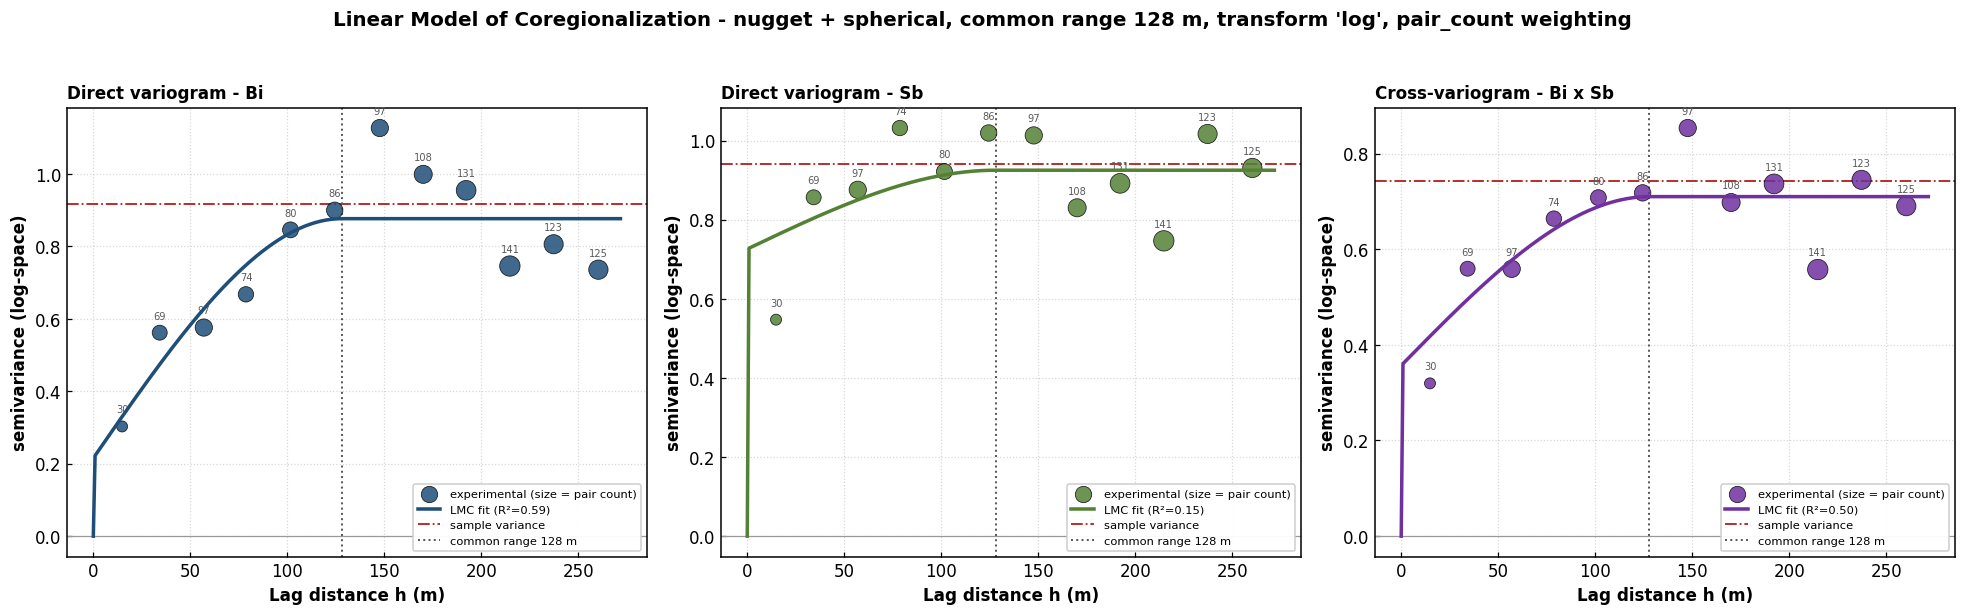

In [10]:
# LMC variogram figure
v11, v22, v12 = M["v11"], M["v22"], M["v12"]
hh = np.linspace(0, edges[-1], 300)
unit = "ppm" if CHOSEN == "none" else f"{CHOSEN}-space"

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
panels = [
    (v11, "11", f"Direct variogram - {PRIMARY}", "#1F4E79"),
    (v22, "22", f"Direct variogram - {SECONDARY}", "#548235"),
    (v12, "12", f"Cross-variogram - {PRIMARY} x {SECONDARY}", "#7030A0"),
]
for ax, (v, key, ttl, col) in zip(axes, panels):
    h, g, cn, dropped = v
    b0, b1 = COEF[key]
    sz = np.clip(18 + 160 * (np.asarray(cn) / max(np.asarray(cn).max(), 1)), 18, 190)
    ax.scatter(h, g, s=sz, c=col, alpha=0.85, edgecolor="black", lw=0.5, zorder=3,
               label="experimental (size = pair count)")
    ax.plot(hh, gamma_model(hh, b0, b1, COMMON_RANGE), color=col, lw=2.3,
            zorder=4, label=f"LMC fit (R²={FIT['fit_r2'][key]:.2f})")
    ax.axhline(_svar[key], color="firebrick", ls="-.", lw=1.2, zorder=2,
               label="sample variance")
    ax.axhline(0, color="0.6", lw=0.8, zorder=1)
    ax.axvline(COMMON_RANGE, color="0.35", ls=":", lw=1.3, zorder=2,
               label=f"common range {COMMON_RANGE:.0f} m")
    for hd, kd in dropped:                      # [FIX K10] say what was dropped
        ax.axvline(hd, color="0.75", ls="--", lw=0.8, zorder=1)
        ax.text(hd, ax.get_ylim()[1], f" n={kd}", rotation=90, fontsize=6,
                color="0.45", va="top")
    for i, c_ in enumerate(cn):
        ax.annotate(str(int(c_)), (h[i], g[i]), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=6.5, color="0.35")
    ax.set_xlabel("Lag distance h (m)", fontweight="bold")
    ax.set_ylabel(f"semivariance ({unit})", fontweight="bold")
    ax.set_title(ttl, fontweight="bold", fontsize=11, loc="left")
    ax.grid(True, ls=":", alpha=0.5)
    ax.legend(fontsize=7.5, loc="lower right", framealpha=0.95)

fig.suptitle(f"Linear Model of Coregionalization - nugget + spherical, common "
             f"range {COMMON_RANGE:.0f} m, transform '{CHOSEN}', "
             f"{VGM_WEIGHTING} weighting",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(outpath("CoK_LMC_variograms.png"))
plt.show()

## Stage 6 - Co-kriging, kriging and cross-validation

In [11]:
# STAGE 6 - Global ordinary co-kriging and ordinary kriging of the primary

GIN = grid_pts[INSIDE]
t0 = time.time()
ck_fit, ck_var_fit, ck_mu, _ = cokrige(SYSD, Y1, Y2, COEF, COMMON_RANGE,
                                       GIN, coords_data)
ok_fit, ok_var_fit, ok_mu, _ = krige(SYSD, Y1, COEF, COMMON_RANGE,
                                     GIN, coords_data)
solve_s = time.time() - t0

# negative variances are a symptom, not a rounding detail
n_neg_ck = int(np.sum(ck_var_fit < -1e-9 * max(sill11, 1)))
n_neg_ok = int(np.sum(ok_var_fit < -1e-9 * max(sill11, 1)))
if n_neg_ck or n_neg_ok:
    qc("WARN", "solver",
       f"negative kriging variance at {n_neg_ck} co-kriging and {n_neg_ok} "
       f"kriging node(s) - a symptom of an ill-conditioned system. The original "
       f"clipped these to zero silently, turning the symptom into a clean zero "
       f"on the uncertainty map.")
ck_var_fit = np.clip(ck_var_fit, 0.0, None)
ok_var_fit = np.clip(ok_var_fit, 0.0, None)

# back-transform, with the Journel correction where the transform is log
if CHOSEN == "none":
    ck_ppm, ok_ppm = ck_fit, ok_fit
else:
    ck_ppm = TF1.back(ck_fit, var=ck_var_fit, lagrange=ck_mu)
    ok_ppm = TF1.back(ok_fit, var=ok_var_fit, lagrange=ok_mu)

n_clip_ck = int(np.sum(np.isfinite(ck_ppm) & (ck_ppm < 0)))
n_clip_ok = int(np.sum(np.isfinite(ok_ppm) & (ok_ppm < 0)))
if n_clip_ck or n_clip_ok:                       # [FIX K16] count the clipping
    qc("INFO", "solver",
       f"{n_clip_ck} co-kriged and {n_clip_ok} kriged node(s) estimated below "
       f"zero and were clipped. Clipping is defensible for a grade but it is a "
       f"bias, and the count is the measure of how far the model wanted to go "
       f"negative.")


def to_grid(v, clip0=True):
    full = np.full(grid_pts.shape[0], np.nan)
    full[INSIDE] = v
    out = full.reshape(X2D.shape)
    return np.where(np.isfinite(out), np.clip(out, 0, None), np.nan) if clip0 else out


CK = to_grid(ck_ppm); OK = to_grid(ok_ppm)
CK_SE = to_grid(np.sqrt(ck_var_fit), clip0=False)
OK_SE = to_grid(np.sqrt(ok_var_fit), clip0=False)
DIFF = CK - OK
SE_DIFF = OK_SE - CK_SE                       # the covariate's value
SE_UNIT = "ppm" if CHOSEN == "none" else f"{CHOSEN}-space"

print(f"Solved {len(GIN):,} nodes in {solve_s:.2f}s   "
      f"(global system, {n_samp} stations, 2n+2 = {2*n_samp+2})")
print(f"  {PRIMARY} co-kriged : {np.nanmin(CK):8.1f} - {np.nanmax(CK):8.1f} ppm "
      f"(mean {np.nanmean(CK):7.1f})")
print(f"  {PRIMARY} kriged    : {np.nanmin(OK):8.1f} - {np.nanmax(OK):8.1f} ppm "
      f"(mean {np.nanmean(OK):7.1f})")
print(f"  CK - OK            : {np.nanmin(DIFF):+8.1f} to {np.nanmax(DIFF):+8.1f} "
      f"ppm  (mean abs {np.nanmean(np.abs(DIFF)):.2f})")
print(f"  SE unit            : {SE_UNIT}"
      + ("" if CHOSEN == "none" else "   <- NOT ppm: the transform is "
                                     f"'{CHOSEN}'"))

# exactness check at data locations
if EXACT_AT_DATA:
    e_ck, _, _, _ = cokrige(SYSD, Y1, Y2, COEF, COMMON_RANGE, coords_data,
                            coords_data)
    resid = np.abs(e_ck - Y1)
    tol = 1e-4 * max(np.std(Y1), 1e-12)
    n_bad = int(np.sum(resid > tol))
    print(f"  exact at data      : max |error| {resid.max():.3e} in fit space "
          f"({n_bad} node(s) above tolerance)")
    if n_bad:
        qc("WARN", "solver",
           f"co-kriging is not reproducing the datum at {n_bad} station(s) "
           f"(max deviation {resid.max():.3e}); the jitter or the conditioning "
           f"is interfering with exact interpolation.")

print("\n" + "=" * 78)
print(f"LEAVE-ONE-OUT CROSS-VALIDATION OF {PRIMARY}   (transform '{CHOSEN}')")
print("=" * 78)
print(f"  {'predictor':<34}{'RMSE':>9}{'MAE':>9}{'R2':>8}{'RMSSE':>8}{'cov95%':>8}")
order = [("kriging", "Ordinary kriging"),
         ("cokriging_mapping", "Co-kriging (MAPPING)"),
         ("cokriging_collocated", "Co-kriging (collocated)"),
         ("regression_on_secondary", f"Regression on {SECONDARY} alone")]
for key, label in order:
    s = CV[key]
    rm = f"{s['rmsse']:.2f}" if np.isfinite(s["rmsse"]) else "   -"
    cv95 = f"{s['cov95']:.0f}" if np.isfinite(s["cov95"]) else "   -"
    print(f"  {label:<34}{s['rmse']:>9.1f}{s['mae']:>9.1f}{s['r2']:>8.3f}"
          f"{rm:>8}{cv95:>8}")
if CV["_n_singular"]:
    qc("WARN", "loocv", f"{CV['_n_singular']} leave-one-out system(s) were "
                        f"singular and are excluded from the metrics.")

k, m = CV["kriging"], CV["cokriging_mapping"]
impr = 100 * (k["rmse"] - m["rmse"]) / k["rmse"] if k["rmse"] > 0 else 0.0
print(f"\n  MAPPING co-kriging vs kriging: {impr:+.1f}% RMSE   <- this is the "
      f"row that describes the maps,")
print(f"  because the secondary is absent at every grid node. Isotopic sampling "
      f"means\n  the two surfaces must nearly coincide; a small number here is "
      f"the correct answer.")

# the collocated claim, put beside its benchmark
col, reg = CV["cokriging_collocated"], CV["regression_on_secondary"]
print("\n" + "-" * 78)
print("  THE COLLOCATED RESULT IS NOT A SPATIAL RESULT")
print("-" * 78)
_sp = "raw ppm" if CHOSEN == "none" else f"'{CHOSEN}' space"
print(f"  co-kriging (collocated)              R2 = {col['r2']:+.3f}   RMSE "
      f"{col['rmse']:8.1f}")
print(f"  regression of {PRIMARY} on {SECONDARY} in {_sp:<11} R2 = "
      f"{reg['r2']:+.3f}   RMSE {reg['rmse']:8.1f}")
print(f"  Spearman({PRIMARY},{SECONDARY})^2 = {best_rs**2:.3f}"
      f"        Pearson^2 = {best_r**2:.3f}")
gap = abs(col["r2"] - reg["r2"])
print(f"\n  The collocated figure and the regression differ by {gap:.3f} in R2, "
      f"against")
print(f"  Spearman^2 = {best_rs**2:.3f}. The benchmark is fitted in the same "
      f"space the model")
print(f"  uses, because a linear fit on raw ppm would be beaten by the "
      f"transform rather")
print(f"  than by any spatial structure, leaving the claim untested.")
print(f"  Keeping {SECONDARY} at the target and asking for {PRIMARY} is a "
      f"REGRESSION, not a")
print(f"  spatial estimate: the number is r^2, and it carries no information "
      f"about")
print(f"  co-kriging. The original notebook reported it as 'collocated "
      f"potential ...")
print(f"  motivates a denser {SECONDARY} survey'.")
print(f"\n  That recommendation is also unattainable for this pair: {PRIMARY} "
      f"and {SECONDARY} are two")
print(f"  channels of ONE XRF measurement on ONE physical sample, so no survey "
      f"design")
print(f"  can densify {SECONDARY} without densifying {PRIMARY}. A collocated "
      f"gain is only")
print(f"  actionable when the secondary is genuinely cheaper or already "
      f"exhaustive -")
print(f"  geophysics, geochemical pathfinders on a coarser assay suite, or "
      f"remote sensing.")
if gap < 0.10:
    qc("WARN", "interpretation",
       f"collocated co-kriging R2 ({col['r2']:.3f}) is within {gap:.3f} of "
       f"plain regression on {SECONDARY} ({reg['r2']:.3f}); it adds no spatial "
       f"information and must not be reported as a co-kriging benefit.")
print("-" * 78)

# variance calibration
print("\n  Kriging-variance calibration (mapping co-kriging):")
print(f"    RMSSE {m['rmsse']:.2f}  - 1.0 means the stated standard error is "
      f"the actual error")
print(f"    95% coverage {m['cov95']:.0f}%  - nominal is 95%")
if np.isfinite(m["rmsse"]) and not (0.8 <= m["rmsse"] <= 1.25):
    qc("WARN", "validation",
       f"RMSSE {m['rmsse']:.2f} is outside [0.8, 1.25]: the mapped standard "
       f"error {'understates' if m['rmsse'] > 1 else 'overstates'} the real "
       f"error by roughly {abs(m['rmsse'] - 1) * 100:.0f}%. The original mapped "
       f"the SE without any calibration check.")
if m["r2"] <= 0:
    qc("WARN", "validation",
       f"LOOCV R2 = {m['r2']:.3f} <= 0: predicting the sample mean everywhere "
       f"beats the co-kriged surface. The map must not be presented as a grade "
       f"model.")
elif m["r2"] < 0.3:
    qc("WARN", "validation",
       f"LOOCV R2 = {m['r2']:.3f}: the surface explains little held-out "
       f"variance. Report this on the face of every map, as is now done.")

Solved 11,081 nodes in 0.51s   (global system, 56 stations, 2n+2 = 114)
  Bi co-kriged :     12.0 -    574.8 ppm (mean   177.7)
  Bi kriged    :     23.0 -    775.9 ppm (mean   178.1)
  CK - OK            :   -224.1 to    +73.8 ppm  (mean abs 23.26)
  SE unit            : log-space   <- NOT ppm: the transform is 'log'
  exact at data      : max |error| 6.693e-10 in fit space (0 node(s) above tolerance)

LEAVE-ONE-OUT CROSS-VALIDATION OF Bi   (transform 'log')
  predictor                              RMSE      MAE      R2   RMSSE  cov95%
  Ordinary kriging                      202.5    119.8   0.192    0.98      93
  Co-kriging (MAPPING)                  205.4    120.9   0.169    0.99      95
  Co-kriging (collocated)                90.3     60.3   0.839    1.10      95
  Regression on Sb alone                131.2     79.9   0.661       -       -

  MAPPING co-kriging vs kriging: -1.5% RMSE   <- this is the row that describes the maps,
  because the secondary is absent at every grid no

C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_7004\505366176.py:168: UserWarning: [WARN] validation: LOOCV R2 = 0.169: the surface explains little held-out variance. Report this on the face of every map, as is now done.
  qc("WARN", "validation",


## Stage 7 - Map furniture and classified surfaces

Surfaces are drawn with `pcolormesh`, so the figure shows the estimated cells and matches the exported raster; the original's `contourf` drew smoothed iso-bands that did not.

In [12]:
# STAGE 7 - Map furniture and classified surfaces

def nice_breaks(vmin, vmax, n=7):
    """[FIX K23] Guaranteed at least two edges, so get_cmap(name, N) is valid."""
    if not (np.isfinite(vmin) and np.isfinite(vmax)) or vmax <= vmin:
        c = vmin if np.isfinite(vmin) else 0.0
        return np.array([c - 0.5, c + 0.5])
    raw = (vmax - vmin) / max(n, 1)
    mag = 10.0 ** np.floor(np.log10(raw))
    step = max(round(raw / mag) * mag, mag)
    e = [np.floor(vmin / step) * step]
    while e[-1] < vmax and len(e) < 200:
        e.append(e[-1] + step)
    if len(e) < 2:
        e.append(e[0] + step)
    return np.array(e)


_BASEMAP_CACHE = {}


def _esri_imagery_utm(x0, x1, y0, y1, zoom="auto"):
    """Esri WorldImagery resampled onto a UTM extent with pyproj only.

    ctx.add_basemap(..., crs=EPSG_UTM) reprojects through rasterio, whose
    bundled PROJ can clash with a conda PROJ database ("CRSError: The EPSG
    code is unknown. PROJ: proj_create_from_database ..."). Here the tiles are
    fetched in Web Mercator with ctx.bounds2img (no CRS handling) and
    resampled bilinearly onto the UTM extent with a pyproj Transformer - the
    library that already projects the samples. Cached: all maps share the
    same extent.
    """
    key = (round(x0, 1), round(x1, 1), round(y0, 1), round(y1, 1), zoom)
    if key in _BASEMAP_CACHE:
        return _BASEMAP_CACHE[key]
    from scipy.ndimage import map_coordinates
    to_wm = Transformer.from_crs(EPSG_UTM, "EPSG:3857", always_xy=True)
    # Web Mercator bounds of the extent (edges densified -> full coverage)
    t = np.linspace(0.0, 1.0, 25)
    ex = np.concatenate([x0 + (x1 - x0) * t, np.full(t.size, x1),
                         x0 + (x1 - x0) * t, np.full(t.size, x0)])
    ey = np.concatenate([np.full(t.size, y0), y0 + (y1 - y0) * t,
                         np.full(t.size, y1), y0 + (y1 - y0) * t])
    mx, my = (np.asarray(v, dtype=float) for v in to_wm.transform(ex, ey))
    img, (wl, wr, wb, wt) = ctx.bounds2img(
        float(mx.min()), float(my.min()), float(mx.max()), float(my.max()),
        zoom=zoom, source=ctx.providers.Esri.WorldImagery, ll=False)
    img = np.asarray(img)
    if img.ndim == 2:
        img = img[:, :, None]
    h, w = img.shape[:2]
    rx, ry = (wr - wl) / w, (wt - wb) / h      # Web Mercator m per tile pixel
    # output raster: ~2 px per tile pixel on the ground, <= 3000 px long side
    px = max(rx * (x1 - x0) / (mx.max() - mx.min()) / 2.0,
             max(x1 - x0, y1 - y0) / 3000.0)
    ncol = max(int(np.ceil((x1 - x0) / px)), 2)
    nrow = max(int(np.ceil((y1 - y0) / px)), 2)
    cx = x0 + (np.arange(ncol) + 0.5) * (x1 - x0) / ncol
    cy = y1 - (np.arange(nrow) + 0.5) * (y1 - y0) / nrow   # row 0 = north
    CX, CY = np.meshgrid(cx, cy)
    MX, MY = (np.asarray(v, dtype=float)
              for v in to_wm.transform(CX.ravel(), CY.ravel()))
    rows, cols = (wt - MY) / ry - 0.5, (MX - wl) / rx - 0.5
    out = np.empty((nrow, ncol, img.shape[2]), dtype=np.uint8)
    for b in range(img.shape[2]):
        v = map_coordinates(img[:, :, b].astype(np.float32), [rows, cols],
                            order=1, mode="nearest")
        out[:, :, b] = np.clip(np.rint(v), 0, 255).astype(np.uint8).reshape(
            nrow, ncol)
    if out.shape[2] == 1:
        out = out[:, :, 0]
    _BASEMAP_CACHE[key] = out
    return out


def add_basemap(ax):
    # The map extent is set FIRST: on a fresh axes the limits are (0, 1), so
    # the tiles were fetched for a 1 m square near E 0 / N 0, far outside the
    # frame that add_furniture() sets later - the imagery never showed.
    x0, x1 = xmin_u - pad_x, xmax_u + pad_x
    y0, y1 = ymin_u - pad_y, ymax_u + pad_y
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    if USE_BASEMAP and CTX_OK:
        try:
            img = _esri_imagery_utm(x0, x1, y0, y1)
            ax.imshow(img, extent=(x0, x1, y0, y1), origin="upper",
                      interpolation="bilinear", alpha=BASEMAP_ALPHA, zorder=0)
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
            ctx.add_attribution(
                ax, ctx.providers.Esri.WorldImagery.get(
                    "attribution", "Esri WorldImagery"), font_size=5)
            return True
        except Exception as exc:                 # [FIX K7] say why, don't pass
            qc("WARN", "basemap", f"tile fetch failed ({type(exc).__name__}: "
                                  f"{exc}); a plain background is used instead.")
    ax.set_facecolor("#d9e1e8")
    return False


def add_furniture(ax, label_axes=True):
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color("black"); s.set_zorder(30)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x)
    ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")     # metres are metres
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(direction="in", length=6, width=1.0, labelsize=9,
                   top=True, right=True)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center"); lab.set_ha("center")
        lab.set_rotation_mode("anchor")
    if label_axes:                               # the original set
        ax.set_xlabel(f"Easting (m)", fontsize=9.5,
                      fontweight="bold")
        ax.set_ylabel(f"Northing (m)", fontsize=9.5,
                      fontweight="bold")

    for r in EXT_RINGS:                          # holes drawn too
        ax.plot(r[:, 0], r[:, 1], color="white", lw=3.0, zorder=9,
                solid_capstyle="round")
        ax.plot(r[:, 0], r[:, 1], color="black", lw=1.3, ls="--", zorder=10)
    for r in HOLE_RINGS:
        ax.plot(r[:, 0], r[:, 1], color="white", lw=2.4, zorder=9)
        ax.plot(r[:, 0], r[:, 1], color="black", lw=1.1, ls=":", zorder=10)

    xext = (xmax_u - xmin_u) + 2 * pad_x
    yext = (ymax_u - ymin_u) + 2 * pad_y
    raw = (xmax_u - xmin_u) * 0.22
    mag = 10 ** int(np.floor(np.log10(raw))) if raw > 0 else 1
    bar = max(round(raw / mag) * mag, mag); seg = bar / 4
    sx = xmin_u - pad_x + 0.045 * xext
    sy = ymin_u - pad_y + 0.05 * yext
    th = 0.012 * yext
    for i in range(4):
        ax.add_patch(Rectangle((sx + i * seg, sy), seg, th,
                               fc=("black" if i % 2 == 0 else "white"),
                               ec="black", lw=1.0, zorder=15))
    for i in range(5):
        ax.text(sx + i * seg, sy - th * 0.5, f"{int(i * seg)}", ha="center",
                va="top", fontsize=7, fontweight="bold", zorder=16,
                path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
    ax.text(sx + bar + seg * 0.25, sy + th * 0.5, "m", ha="left", va="center",
            fontsize=8, fontweight="bold", zorder=16,
            path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
    nx_ = xmax_u + pad_x - 0.075 * xext
    ny_ = ymax_u + pad_y - 0.10 * yext
    al = 0.07 * yext
    for col, lw, z in (("white", 4.5, 16), ("black", 1.8, 17)):
        ax.annotate("", xy=(nx_, ny_), xytext=(nx_, ny_ - al), zorder=z,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=lw,
                                    mutation_scale=22))
    ax.text(nx_, ny_ + al * 0.18, "N", ha="center", va="bottom", fontsize=15,
            fontweight="bold", zorder=18, color="white",
            path_effects=[mpe.withStroke(linewidth=3.5, foreground="black")])


def draw_surface(ax, Z, breaks, cmap_obj, norm_obj, clip=True):
    """[FIX K17] pcolormesh, NOT contourf.

    contourf draws smoothed iso-bands that do not correspond to the estimated
    cells, so the published figure and the exported .asc showed different
    surfaces. pcolormesh paints the cells themselves, which is what the raster
    contains.
    [FIX K19] `extend` is set only where the breaks genuinely clip the data.
    """
    ex = float(cellsize) / 2.0
    qm = ax.pcolormesh(
        np.append(gx - ex, gx[-1] + ex), np.append(gy - ex, gy[-1] + ex),
        np.ma.masked_invalid(Z), cmap=cmap_obj, norm=norm_obj,
        alpha=SURFACE_ALPHA, shading="flat", zorder=2, rasterized=True)
    if clip:
        patch = PathPatch(CLIP_PATH, transform=ax.transData, fc="none",
                          ec="none", zorder=4)
        ax.add_patch(patch)
        qm.set_clip_path(patch)
    return qm


def which_extend(Z, breaks):
    z = Z[np.isfinite(Z)]
    if z.size == 0:
        return "neither"
    lo, hi = z.min() < breaks[0], z.max() > breaks[-1]
    return "both" if (lo and hi) else "min" if lo else "max" if hi else "neither"


def add_cbar(fig, ax, breaks, cmap_obj, norm_obj, label, Z):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm_obj, cmap=cmap_obj), ax=ax,
                      fraction=0.043, pad=0.012, boundaries=breaks, ticks=breaks,
                      spacing="proportional", extend=which_extend(Z, breaks))
    cb.set_label(label, fontsize=10, fontweight="bold")
    cb.ax.tick_params(labelsize=8)
    return cb


def info_box(ax, extra=""):
    m = CV["cokriging_mapping"]
    txt = (f"METHOD    : ordinary co-kriging, LMC nugget+spherical\n"
           f"PRIMARY   : {PRIMARY}     SECONDARY : {SECONDARY} "
           f"(Spearman {best_rs:+.2f}, n={best_n})\n"
           f"TRANSFORM : {CHOSEN}      RANGE : {COMMON_RANGE:.0f} m"
           f"{'  [on bound]' if FIT['on_bound'] else ''}\n"
           f"STATIONS  : {n_samp} (from {n_rows_raw} rows at "
           f"{STATION_TOL_M:.0f} m)\n"
           f"LOOCV     : RMSE {m['rmse']:.0f} ppm   R² {m['r2']:+.2f}   "
           f"RMSSE {m['rmsse']:.2f}   cov95 {m['cov95']:.0f}%\n"
           f"CRS       : {EPSG_UTM}   cell {cellsize:.2f} m (square)")
    if m["r2"] <= 0.30:
        txt += (f"\nCAUTION   : LOOCV R² {m['r2']:+.2f} — scoping-level "
                f"Exploration Target,\n            not a grade model")
    if extra:
        txt += "\n" + extra
    ax.text(xmax_u + pad_x - 0.02 * (xmax_u - xmin_u),
            ymin_u - pad_y + 0.02 * (ymax_u - ymin_u), txt, ha="right",
            va="bottom", fontsize=7, family="monospace", linespacing=1.5,
            zorder=20,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.4", lw=0.8,
                      alpha=0.93))


both = np.concatenate([CK[np.isfinite(CK)], OK[np.isfinite(OK)]])
gbreaks = nice_breaks(float(both.min()), float(both.max()), N_GRADE_CLASSES)
gcmap = plt.get_cmap(GRADE_CMAP, len(gbreaks) - 1)
gnorm = BoundaryNorm(gbreaks, gcmap.N)

se_all = np.concatenate([CK_SE[np.isfinite(CK_SE)], OK_SE[np.isfinite(OK_SE)]])
sebreaks = nice_breaks(float(se_all.min()), float(se_all.max()), N_SE_CLASSES)
secmap = plt.get_cmap("cividis", len(sebreaks) - 1)
senorm = BoundaryNorm(sebreaks, secmap.N)
print(f"Grade classes: {len(gbreaks)-1} over [{gbreaks[0]:.0f}, "
      f"{gbreaks[-1]:.0f}] ppm    SE classes: {len(sebreaks)-1} over "
      f"[{sebreaks[0]:.3g}, {sebreaks[-1]:.3g}] {SE_UNIT}")

Grade classes: 8 over [0, 800] ppm    SE classes: 7 over [0.49, 0.98] log-space


### The co-kriged grade map

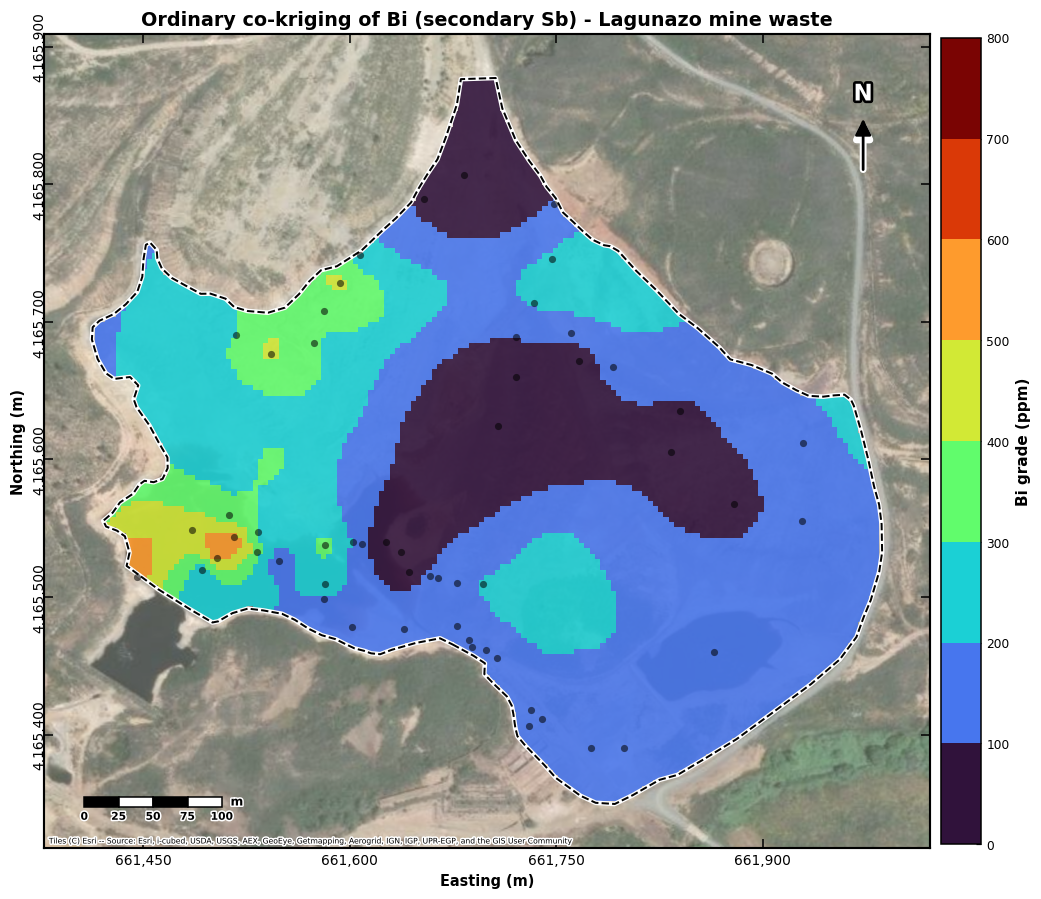

In [13]:
# the co-kriged grade map
fig, ax = plt.subplots(figsize=(11, 9.6))
add_basemap(ax)
draw_surface(ax, CK, gbreaks, gcmap, gnorm)
if SHOW_SAMPLES:
    ax.scatter(coords_data[:, 0], coords_data[:, 1], s=22, c="black",
               alpha=0.55, lw=0, zorder=11, label=f"{n_samp} stations")
add_furniture(ax)
add_cbar(fig, ax, gbreaks, gcmap, gnorm,
         f"{PRIMARY} grade (ppm)", CK)
ax.set_title(f"Ordinary co-kriging of {PRIMARY} (secondary {SECONDARY}) - "
             f"Lagunazo mine waste", fontsize=12.5, fontweight="bold")
fig.savefig(outpath("CoK_grade_map.png"))
fig.savefig(outpath("CoK_grade_map.pdf"))
plt.show()

### Estimate and uncertainty

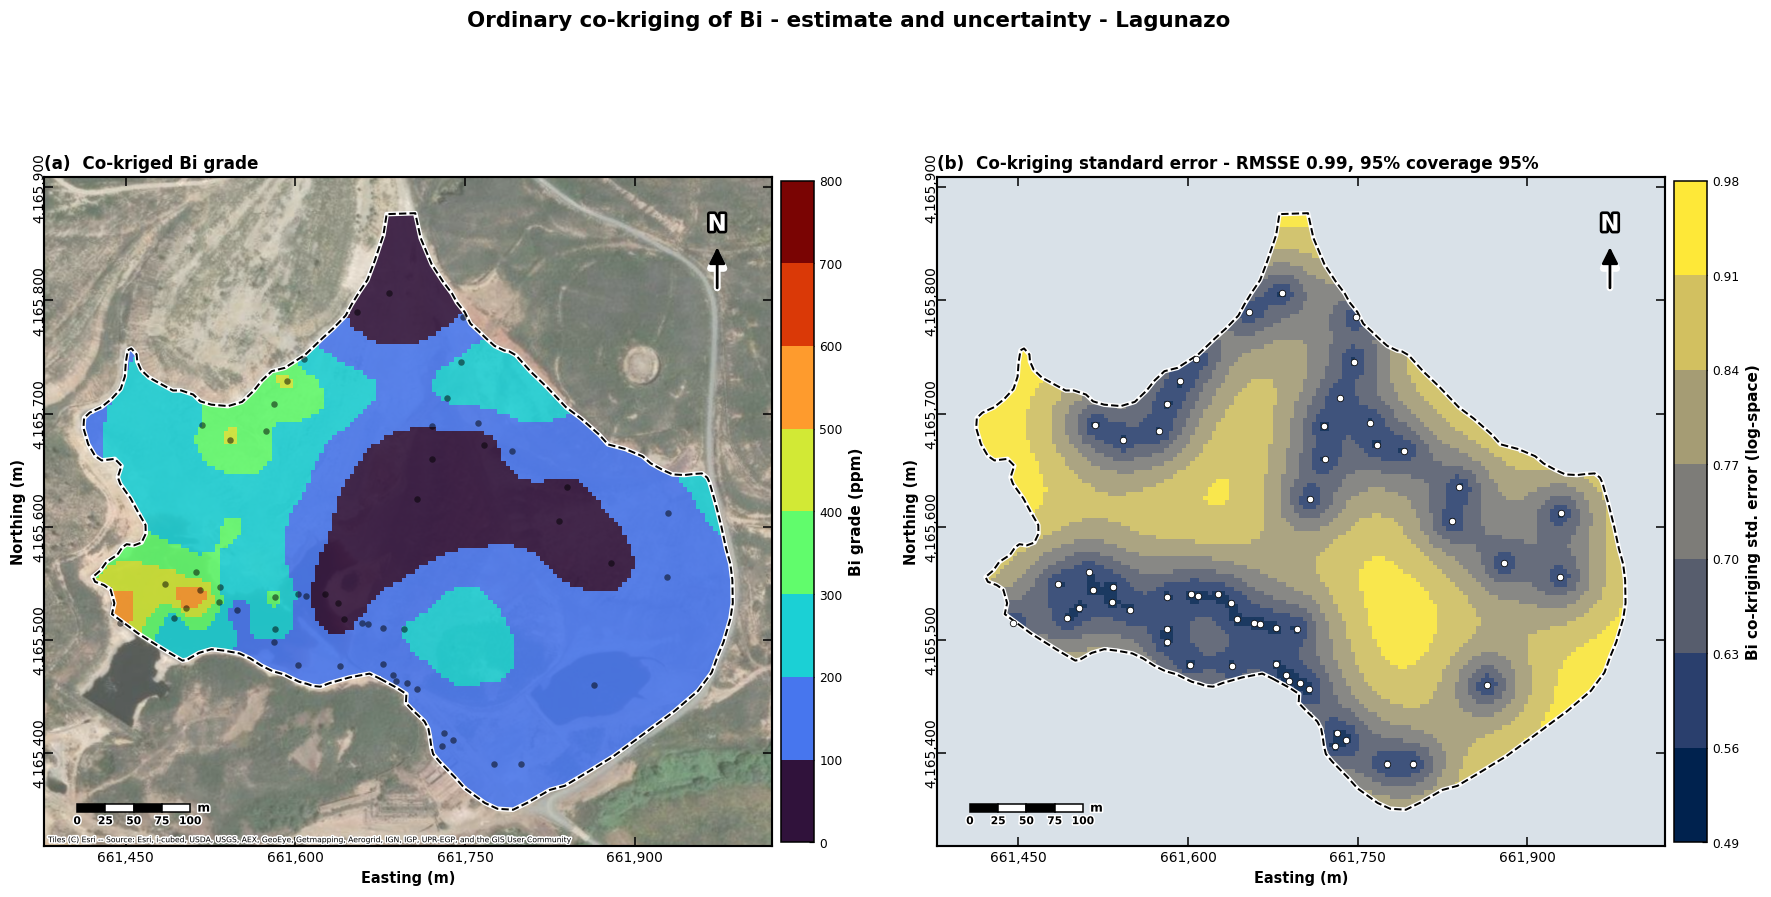

In [14]:
# grade + standard error, side by side
fig, (axg, axe) = plt.subplots(1, 2, figsize=(19.5, 9.2),
                               gridspec_kw={"wspace": 0.16})
add_basemap(axg)
draw_surface(axg, CK, gbreaks, gcmap, gnorm)
if SHOW_SAMPLES:
    axg.scatter(coords_data[:, 0], coords_data[:, 1], s=18, c="black",
                alpha=0.5, lw=0, zorder=11)
add_furniture(axg)
add_cbar(fig, axg, gbreaks, gcmap, gnorm, f"{PRIMARY} grade (ppm)", CK)
axg.set_title(f"(a)  Co-kriged {PRIMARY} grade", fontsize=11,
              fontweight="bold", loc="left")

axe.set_facecolor("#d9e1e8")
draw_surface(axe, CK_SE, sebreaks, secmap, senorm)
if SHOW_SAMPLES:
    axe.scatter(coords_data[:, 0], coords_data[:, 1], s=18, c="white",
                edgecolor="black", lw=0.5, zorder=11)
add_furniture(axe)
add_cbar(fig, axe, sebreaks, secmap, senorm,
         f"{PRIMARY} co-kriging std. error ({SE_UNIT})", CK_SE)
_m = CV["cokriging_mapping"]
axe.set_title(f"(b)  Co-kriging standard error - RMSSE {_m['rmsse']:.2f}, "
              f"95% coverage {_m['cov95']:.0f}%", fontsize=11,
              fontweight="bold", loc="left")
fig.suptitle(f"Ordinary co-kriging of {PRIMARY} - estimate and uncertainty - "
             f"Lagunazo", fontsize=14, fontweight="bold", y=0.99)
fig.savefig(outpath("CoK_grade_and_SE.png"))
fig.savefig(outpath("CoK_grade_and_SE.pdf"))
plt.show()

### Kriging versus co-kriging, and what the covariate bought

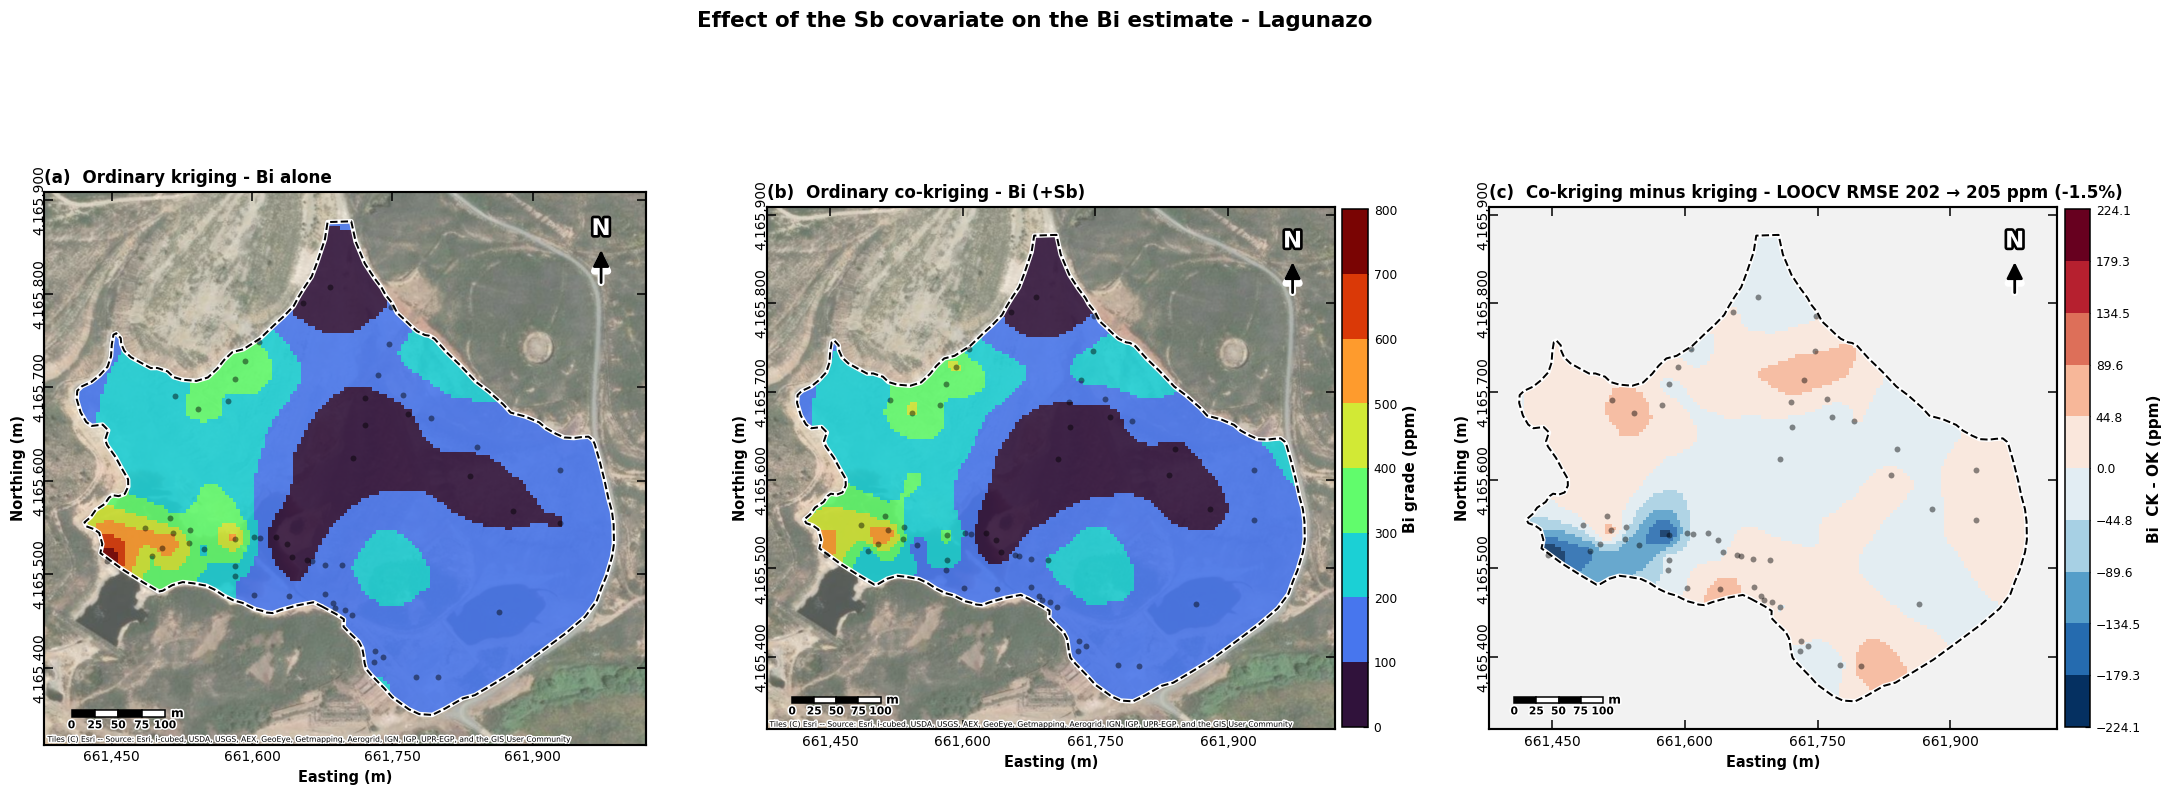

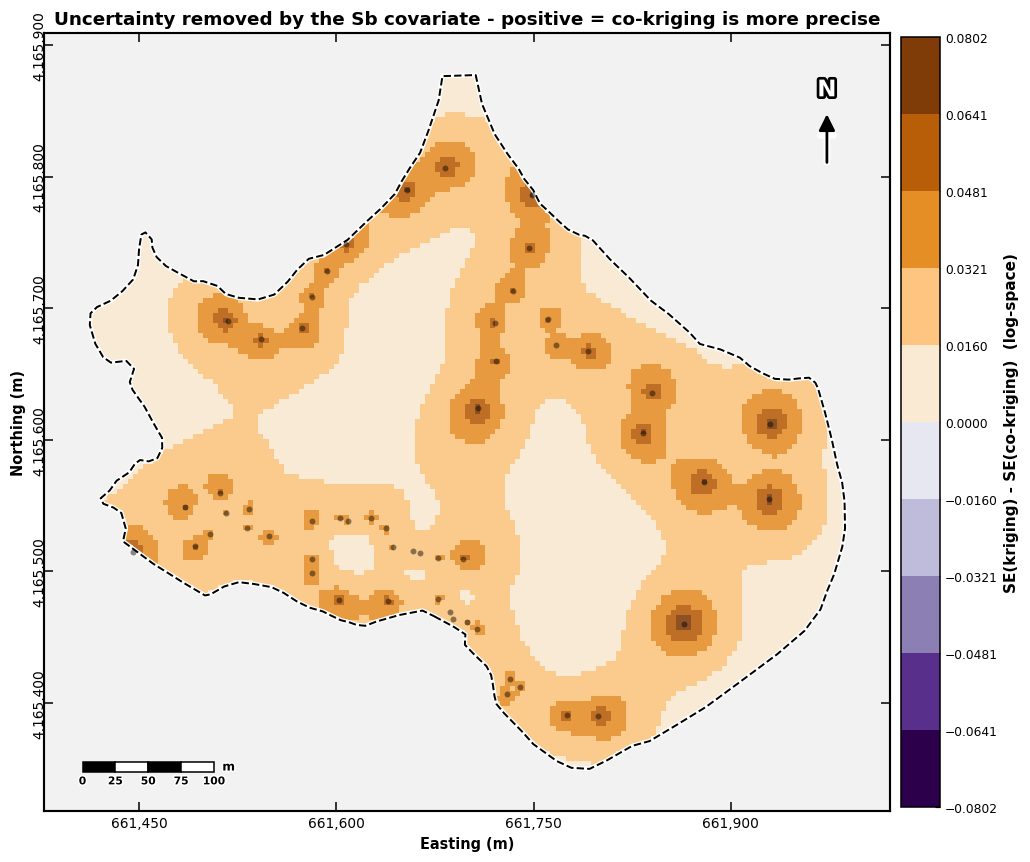

In [15]:
# kriging vs co-kriging, and what the covariate bought
dmax = float(np.nanmax(np.abs(DIFF)))
dmax = max(dmax if np.isfinite(dmax) else 1.0, 1e-6)
dlev = np.linspace(-dmax, dmax, 11)
dcmap = plt.get_cmap("RdBu_r", len(dlev) - 1)
dnorm = BoundaryNorm(dlev, dcmap.N)

fig, axes = plt.subplots(1, 3, figsize=(24, 8.4), gridspec_kw={"wspace": 0.2})
for ax, Z, ttl in [(axes[0], OK, f"(a)  Ordinary kriging - {PRIMARY} alone"),
                   (axes[1], CK, f"(b)  Ordinary co-kriging - {PRIMARY} "
                                 f"(+{SECONDARY})")]:
    add_basemap(ax)
    draw_surface(ax, Z, gbreaks, gcmap, gnorm)
    if SHOW_SAMPLES:
        ax.scatter(coords_data[:, 0], coords_data[:, 1], s=15, c="black",
                   alpha=0.45, lw=0, zorder=11)
    add_furniture(ax)
    ax.set_title(ttl, fontsize=11, fontweight="bold", loc="left")
add_cbar(fig, axes[1], gbreaks, gcmap, gnorm, f"{PRIMARY} grade (ppm)", CK)

axes[2].set_facecolor("#f2f2f2")
draw_surface(axes[2], DIFF, dlev, dcmap, dnorm)
if SHOW_SAMPLES:
    axes[2].scatter(coords_data[:, 0], coords_data[:, 1], s=15, c="black",
                    alpha=0.45, lw=0, zorder=11)
add_furniture(axes[2])
add_cbar(fig, axes[2], dlev, dcmap, dnorm,
         f"{PRIMARY}  CK - OK (ppm)", DIFF)
_k, _m = CV["kriging"], CV["cokriging_mapping"]
axes[2].set_title(f"(c)  Co-kriging minus kriging - LOOCV RMSE "
                  f"{_k['rmse']:.0f} → {_m['rmse']:.0f} ppm "
                  f"({100*(_k['rmse']-_m['rmse'])/max(_k['rmse'],1e-9):+.1f}%)",
                  fontsize=11, fontweight="bold", loc="left")
fig.suptitle(f"Effect of the {SECONDARY} covariate on the {PRIMARY} estimate - "
             f"Lagunazo", fontsize=14, fontweight="bold", y=0.99)
fig.savefig(outpath("CoK_vs_OK_comparison.png"))
fig.savefig(outpath("CoK_vs_OK_comparison.pdf"))
plt.show()

# the uncertainty the covariate actually removed
fig, ax = plt.subplots(figsize=(10.5, 9.2))
sd = SE_DIFF[np.isfinite(SE_DIFF)]
smax = max(float(np.nanmax(np.abs(sd))) if sd.size else 1.0, 1e-9)
slev = np.linspace(-smax, smax, 11)
scmap = plt.get_cmap("PuOr_r", len(slev) - 1)
snorm = BoundaryNorm(slev, scmap.N)
ax.set_facecolor("#f2f2f2")
draw_surface(ax, SE_DIFF, slev, scmap, snorm)
if SHOW_SAMPLES:
    ax.scatter(coords_data[:, 0], coords_data[:, 1], s=15, c="black",
               alpha=0.45, lw=0, zorder=11)
add_furniture(ax)
add_cbar(fig, ax, slev, scmap, snorm,
         f"SE(kriging) - SE(co-kriging)  ({SE_UNIT})", SE_DIFF)
ax.set_title(f"Uncertainty removed by the {SECONDARY} covariate - "
             f"positive = co-kriging is more precise",
             fontsize=12, fontweight="bold")
fig.savefig(outpath("CoK_SE_reduction.png"))
plt.show()

## Stage 8 - Rasters, tables and run manifest

In [16]:
# STAGE 8 - Rasters with CRS and units, tables, run manifest

def write_esri_ascii(path, Z2D, unit_note):
    """[FIX K1, K20] ESRI ASCII has ONE cellsize field, so a non-square grid
    cannot be represented. The grid is verified square before anything is
    written, a .prj carries the CRS, and a _UNITS.txt states the unit - none of
    which the original produced."""
    if not SQUARE:
        raise RuntimeError("refusing to export: grid cells are not square, so "
                           "a single ESRI ASCII cellsize would misgeoreference "
                           "the raster (this is defect K1).")
    arr = np.where(np.isfinite(Z2D), Z2D, -9999.0)[::-1, :]
    with open(path, "w") as f:
        f.write(f"ncols {arr.shape[1]}\nnrows {arr.shape[0]}\n")
        f.write(f"xllcorner {gx.min() - cellsize / 2:.4f}\n")
        f.write(f"yllcorner {gy.min() - cellsize / 2:.4f}\n")
        f.write(f"cellsize {cellsize:.6f}\nNODATA_value -9999\n")
        np.savetxt(f, arr, fmt="%.4f")
    with open(os.path.splitext(path)[0] + ".prj", "w") as f:
        f.write(CRS.from_user_input(EPSG_UTM).to_wkt())
    with open(os.path.splitext(path)[0] + "_UNITS.txt", "w") as f:
        f.write(unit_note + f"\nCRS: {EPSG_UTM}\ncellsize: {cellsize:.6f} m "
                            f"(square)\nNODATA: -9999\n")
    return os.path.basename(path)


def sha256_of(path, block=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


rasters = []
rasters.append(write_esri_ascii(
    outpath(f"CoK_{PRIMARY}_cokriged_ppm_UTM29N.asc"), CK,
    f"{PRIMARY} co-kriged grade, ppm. Secondary {SECONDARY}. "
    f"Transform '{CHOSEN}', LMC nugget+spherical, range {COMMON_RANGE:.1f} m."))
rasters.append(write_esri_ascii(
    outpath(f"CoK_{PRIMARY}_kriged_ppm_UTM29N.asc"), OK,
    f"{PRIMARY} ordinary-kriged grade, ppm (primary alone). "
    f"Transform '{CHOSEN}'."))
_tag = "ppm" if CHOSEN == "none" else f"{CHOSEN}space"
rasters.append(write_esri_ascii(
    outpath(f"CoK_{PRIMARY}_cokriging_SE_{_tag}_UTM29N.asc"), CK_SE,
    f"{PRIMARY} co-kriging prediction standard error, units: {SE_UNIT}. "
    f"NOT ppm unless the transform is 'none'. "
    f"RMSSE {CV['cokriging_mapping']['rmsse']:.3f}, "
    f"95% coverage {CV['cokriging_mapping']['cov95']:.1f}%."))
rasters.append(write_esri_ascii(
    outpath(f"CoK_{PRIMARY}_kriging_SE_{_tag}_UTM29N.asc"), OK_SE,
    f"{PRIMARY} ordinary-kriging prediction standard error, units: {SE_UNIT}."))

# tables
written = []
if EXPORT_TABLES:
    cvt = pd.DataFrame({
        k: {"RMSE_ppm": v["rmse"], "MAE_ppm": v["mae"], "R2_ppm": v["r2"],
            "RMSSE": v["rmsse"], "coverage95_pct": v["cov95"]}
        for k, v in CV.items() if isinstance(v, dict)}).T
    vgm_long = pd.concat([
        pd.DataFrame({"structure": s, "lag_centre_m": v[0], "gamma": v[1],
                      "n_pairs": v[2]})
        for s, v in (("gamma_11", M["v11"]), ("gamma_22", M["v22"]),
                     ("gamma_12", M["v12"]))], ignore_index=True)
    lmc_tbl = pd.DataFrame({
        k: {"nugget": COEF[k][0], "spherical_sill": COEF[k][1],
            "total_sill": COEF[k][0] + COEF[k][1], "sample_variance": _svar[k],
            "sill_over_variance": (COEF[k][0] + COEF[k][1]) / _svar[k]
            if abs(_svar[k]) > 1e-12 else np.nan,
            "weighted_fit_R2": FIT["fit_r2"][k]} for k in ("11", "22", "12")}).T
    per_station = pd.DataFrame({
        "X_utm": coords_data[:, 0], "Y_utm": coords_data[:, 1],
        "n_reps": PAIR_DF["n_reps"].to_numpy(),
        f"{PRIMARY}_obs_ppm": z1, f"{SECONDARY}_obs_ppm": z2,
        "kriging_pred_ppm": CV["kriging"]["pred_ppm"],
        "cokriging_mapping_pred_ppm": CV["cokriging_mapping"]["pred_ppm"],
        "cokriging_collocated_pred_ppm": CV["cokriging_collocated"]["pred_ppm"],
        "regression_on_secondary_pred_ppm":
            CV["regression_on_secondary"]["pred_ppm"]})
    lo_, la_ = to_ll.transform(coords_data[:, 0], coords_data[:, 1])
    per_station.insert(0, "Lat", la_); per_station.insert(0, "Lon", lo_)

    tables = {
        "element_census.csv": CENSUS_RAW,
        "pair_selection.csv": PAIRS.drop(columns=["abs_selector"]),
        "transform_trials.csv": TRIALS_DF,
        "lmc_coefficients.csv": lmc_tbl,
        "experimental_variograms.csv": vgm_long,
        "crossvalidation_summary.csv": cvt,
        "crossvalidation_per_station.csv": per_station,
        "qc_log.csv": pd.DataFrame(QC_LOG),
    }
    for name, obj in tables.items():
        obj.to_csv(outpath(name))
        written.append(name)

MANIFEST = {
    "notebook": "Ordinary_CoKriging_Lagunazo_fixed.ipynb",
    "run_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": ENV,
    "inputs": {p: {"sha256": sha256_of(p), "bytes": os.path.getsize(p)}
               for p in (CSV_DATA, KMZ_FILE)},
    "geometry": {
        "polygon_parts": int(n_parts), "interior_rings": int(n_holes),
        "area_ha": round(POLY.area / 1e4, 3),
        "nx": int(nx), "ny": int(ny), "cellsize_m": round(float(cellsize), 6),
        "cells_square": bool(SQUARE), "dx_m": round(dx, 6), "dy_m": round(dy, 6),
        "nodes_inside": int(INSIDE.sum()),
        "nn1_spacing_m": round(nn1_spacing, 3),
        "nn3_spacing_m": round(nn3_spacing, 3),
        "max_separation_m": round(max_sep, 2)},
    "data": {
        "measurement_rows": int(n_rows_raw),
        "stations_at_tolerance": int(n_stations),
        "stations_exact_coords": int(n_exact),
        "stations_in_model": int(n_samp),
        "nondetects_substituted": int(n_sub_total),
        "half_min_values_ppm": {k: round(v, 6) for k, v in SUBS.items()}},
    "model": {
        "primary": PRIMARY, "secondary": SECONDARY,
        "pair_selected_on": PAIR_SELECT_ON,
        "spearman": round(float(best_rs), 4), "pearson": round(float(best_r), 4),
        "pair_n": int(best_n),
        "transform": CHOSEN, "common_range_m": round(float(COMMON_RANGE), 3),
        "range_on_bound": bool(FIT["on_bound"]),
        "coefficients": {k: [round(float(v), 4) for v in COEF[k]]
                         for k in COEF},
        "fit_r2": {k: round(float(v), 4) for k, v in FIT["fit_r2"].items()},
        "cond_cokriging": float(SYSD["cond_ck"]),
        "cond_kriging": float(SYSD["cond_ok"]),
        "negative_variance_nodes": {"cokriging": n_neg_ck, "kriging": n_neg_ok},
        "clipped_negative_estimate_nodes": {"cokriging": n_clip_ck,
                                            "kriging": n_clip_ok}},
    "validation": {k: {kk: (None if not np.isfinite(vv) else round(float(vv), 4))
                       for kk, vv in (("rmse_ppm", v["rmse"]),
                                      ("mae_ppm", v["mae"]),
                                      ("r2_ppm", v["r2"]),
                                      ("rmsse", v["rmsse"]),
                                      ("coverage95_pct", v["cov95"]))}
                   for k, v in CV.items() if isinstance(v, dict)},
    "config": {k: v for k, v in sorted(globals().items())
               if k.isupper() and isinstance(
                   v, (int, float, str, bool, list, tuple, type(None)))
               and k not in ("ENV",)},
    "qc_log": QC_LOG,
}
with open(outpath("run_manifest.json"), "w", encoding="utf-8") as fh:
    json.dump(MANIFEST, fh, indent=2, default=str)
written.append("run_manifest.json")

print(f"Written to {OUT_DIR}/\n")
print("  rasters (.asc + .prj + _UNITS.txt each):")
for r in rasters:
    print(f"    {r:<48}{os.path.getsize(outpath(r)):>10,} B")
print(f"\n  tables and manifest:")
for f in written:
    print(f"    {f:<48}{os.path.getsize(outpath(f)):>10,} B")
figs = ["CoK_LMC_variograms.png", "CoK_grade_map.png", "CoK_grade_and_SE.png",
        "CoK_vs_OK_comparison.png", "CoK_SE_reduction.png"]
print(f"\n  figures:")
for f in figs:
    if os.path.exists(outpath(f)):
        print(f"    {f:<48}{os.path.getsize(outpath(f)):>10,} B")

Written to results_cokriging/

  rasters (.asc + .prj + _UNITS.txt each):
    CoK_Bi_cokriged_ppm_UTM29N.asc                     204,953 B
    CoK_Bi_kriged_ppm_UTM29N.asc                       205,041 B
    CoK_Bi_cokriging_SE_logspace_UTM29N.asc            185,140 B
    CoK_Bi_kriging_SE_logspace_UTM29N.asc              185,140 B

  tables and manifest:
    element_census.csv                                     107 B
    pair_selection.csv                                     749 B
    transform_trials.csv                                   373 B
    lmc_coefficients.csv                                   442 B
    experimental_variograms.csv                          1,974 B
    crossvalidation_summary.csv                            459 B
    crossvalidation_per_station.csv                     10,074 B
    qc_log.csv                                           1,467 B
    run_manifest.json                                   15,823 B

  figures:
    CoK_LMC_variograms.png                   

## Summary

In [17]:
# Summary

_k, _m, _c, _r = (CV["kriging"], CV["cokriging_mapping"],
                  CV["cokriging_collocated"], CV["regression_on_secondary"])
print("=" * 78)
print(f"  ORDINARY CO-KRIGING COMPLETE - {PRIMARY} (secondary {SECONDARY})")
print("=" * 78)
print(f"  Measurement rows / stations : {n_rows_raw} -> {n_stations} at "
      f"{STATION_TOL_M:.0f} m -> {n_samp} in the model")
print(f"  Pair (on {PAIR_SELECT_ON:<9})        : {best_a}-{best_b}   "
      f"Spearman {best_rs:+.3f}, Pearson {best_r:+.3f}, n = {best_n}")
print(f"  Transform adopted           : {CHOSEN}")
print(f"  LMC common range            : {COMMON_RANGE:.1f} m"
      f"{'  [ON BOUND]' if FIT['on_bound'] else ''}")
print(f"  LMC fit R2 (11 / 22 / 12)   : {FIT['fit_r2']['11']:.2f} / "
      f"{FIT['fit_r2']['22']:.2f} / {FIT['fit_r2']['12']:.2f}")
print(f"  nugget : sill ({PRIMARY})          : "
      f"{COEF['11'][0] / max(sill11, 1e-12):.3f}")
print(f"  Grid                        : {nx} x {ny}, cell {cellsize:.2f} m, "
      f"square = {SQUARE}")
print(f"  Domain                      : {POLY.area/1e4:.1f} ha, "
      f"{n_holes} interior ring(s) excluded")
print(f"  Co-kriged {PRIMARY:<3}               : {np.nanmin(CK):.0f}-"
      f"{np.nanmax(CK):.0f} ppm (mean {np.nanmean(CK):.0f})")
print(f"  Condition number            : {SYSD['cond_ck']:.2e}")
print()
print(f"  {'LOOCV predictor':<34}{'RMSE':>9}{'R2':>8}{'RMSSE':>8}{'cov95':>8}")
for key, label in (("kriging", "Ordinary kriging"),
                   ("cokriging_mapping", "Co-kriging (MAPPING = the maps)"),
                   ("cokriging_collocated", "Co-kriging (collocated)"),
                   ("regression_on_secondary", f"Regression on {SECONDARY}")):
    s = CV[key]
    rm = f"{s['rmsse']:.2f}" if np.isfinite(s["rmsse"]) else "   -"
    cc = f"{s['cov95']:.0f}" if np.isfinite(s["cov95"]) else "   -"
    print(f"  {label:<34}{s['rmse']:>9.1f}{s['r2']:>8.3f}{rm:>8}{cc:>8}")
print()
print("  READING OF THE RESULT")
print(f"    Co-kriging changes the mapped {PRIMARY} surface by "
      f"{100*(_k['rmse']-_m['rmse'])/max(_k['rmse'],1e-9):+.1f}% in LOOCV RMSE.")
print(f"    Sampling is isotopic, so the secondary is absent at every grid "
      f"node and")
print(f"    this near-equality is the correct answer, not a shortfall.")
print(f"    The collocated figure (R2 {_c['r2']:.2f}) matches plain regression "
      f"on {SECONDARY}")
print(f"    (R2 {_r['r2']:.2f}) and is therefore r^2, not a spatial result; and "
      f"because")
print(f"    {PRIMARY} and {SECONDARY} come from one XRF measurement, no survey "
      f"can realise it.")
if _m["r2"] <= 0.30:
    print(f"    LOOCV R2 = {_m['r2']:+.2f}: this is a scoping-level "
          f"Exploration Target in")
    print(f"    JORC/PERC terms, not a grade model, and every map now carries "
          f"that caveat.")
drops = [e for e in QC_LOG if e["level"] == "DROP"]
warns = [e for e in QC_LOG if e["level"] == "WARN"]
print(f"\n  Quality events              : {len(drops)} DROP, {len(warns)} WARN")
print("=" * 78)
print("\nQuality log:")
qc_report()

  ORDINARY CO-KRIGING COMPLETE - Bi (secondary Sb)
  Measurement rows / stations : 274 -> 68 at 5 m -> 56 in the model
  Pair (on spearman )        : Bi-Sb   Spearman +0.823, Pearson +0.816, n = 56
  Transform adopted           : log
  LMC common range            : 127.9 m
  LMC fit R2 (11 / 22 / 12)   : 0.59 / 0.15 / 0.50
  nugget : sill (Bi)          : 0.246
  Grid                        : 151 x 138, cell 3.83 m, square = True
  Domain                      : 16.2 ha, 0 interior ring(s) excluded
  Co-kriged Bi                : 12-575 ppm (mean 178)
  Condition number            : 2.26e+02

  LOOCV predictor                        RMSE      R2   RMSSE   cov95
  Ordinary kriging                      202.5   0.192    0.98      93
  Co-kriging (MAPPING = the maps)       205.4   0.169    0.99      95
  Co-kriging (collocated)                90.3   0.839    1.10      95
  Regression on Sb                      131.2   0.661       -       -

  READING OF THE RESULT
    Co-kriging changes the 